# Lectures 28-30

__Today:__

* Finish Newton's Method material
* Start Python Unit 4 (image processing) 🎉

__Future:__

* Next week is finals week. There is no final, or meeting time for next week – there will be office hours.

## Analyzing Newton's Method

Let $f(x) = x^3 - 2x + 2$. For each value of $z$ in `np.linspace(-2,2,1000)`, apply Newton's method 7 times, and call the result `results`. For how many of these 1000 values do we have $-0.001 < f(\text{results}) < 0.001$?

Recall that $f(\text{results})=0 $ if we end up with the true root, and $f(\text{results}) \approx 0 $ if the result is almost a root.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("darkgrid")

In [2]:
f = lambda x: x**3-2*x+2
df = lambda x: 3*x**2 - 2
newt = lambda z: z - f(z)/df(z)

__Idea:__ Each row of `arr` will be the result of applying Newton's method 7 times to a single point in `np.linspace(-2,2,1000)`. "A row for each point"

In [7]:
z = np.linspace(-2,2,1000)  #instead of one initial guess, we'll try 1000 points on the interval [-2, 2].
reps = 7
arr = np.zeros((len(z),reps+1))  #columns are the iterations of newton's method, the rows represent each initial value (of which there are 1000)
arr[:,0] = z  #same except for using the [:,0] instead of [0]

for i in range(reps):
    arr[:,i+1] = newt(arr[:,i])

In [9]:
results = arr[:,-1]  #last column holds the results, the final x-values from Newton's method

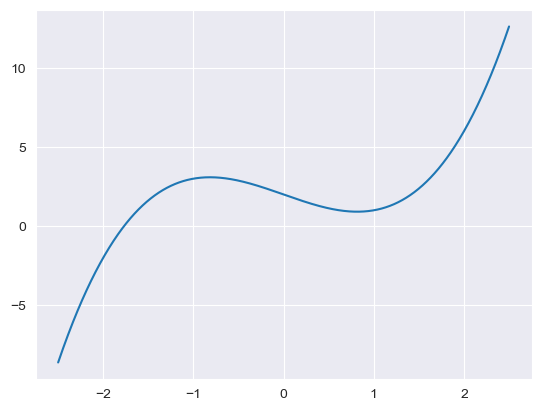

In [11]:
fig,ax = plt.subplots()
x = np.linspace(-2.5,2.5,1000)
ax.plot(x,f(x));

In [13]:
good_bool = np.abs(f(results)) < 0.001   #check the absolute value of the y-values from Newton's method

In [15]:
good_bool.shape

(1000,)

The length makes sense, because we have 1000 points.

Out of the 1000 input points, we use `.sum()` to determine that 327 points lead to a good estimate for a zero of $f$.

In [19]:
good_bool.sum()

327

Let's plot these points and see where they live. There's a mistake here, we need the size of `pts` to match the size of the $y$-values. There's a pretty easy fix for this.

In [21]:
good_pts = z[good_bool]
ax.plot(good_pts,0,'ko')


ValueError: x and y must have same first dimension, but have shapes (327,) and (1,)

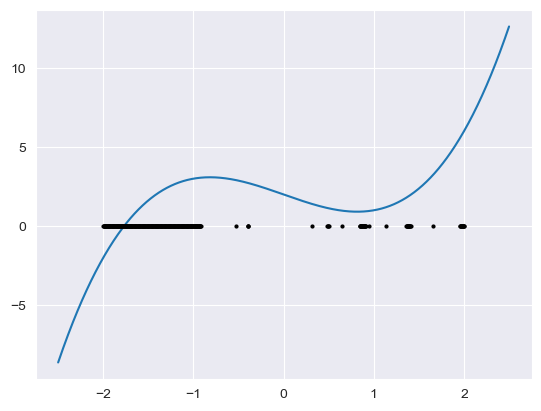

In [23]:
ax.plot(good_pts,np.zeros(len(good_pts)),'ko',markersize=2);
fig

Let's update this plot to now have the bad points in red.

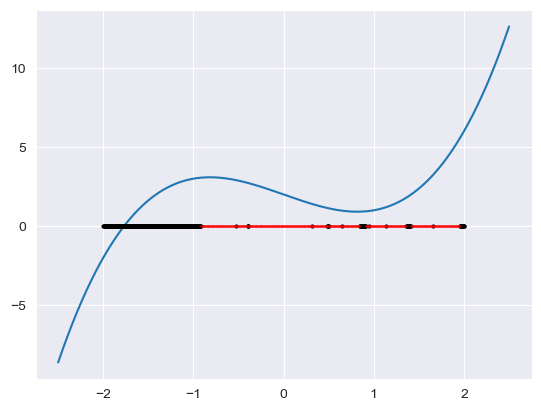

In [25]:
bad_pts = z[~good_bool] #Negate the boolean to get the bad points
ax.plot(bad_pts,np.zeros(len(bad_pts)),'ro',markersize=1, alpha = 0.25); #smaller markers so the scattered black markers still show
#alpha determines the transparency of a point. alpha = 0 is totally invisible, and alpha = 1 is totally opaque.
fig

## Newton's Method vs. Bisect Method: Timing and Tradeoffs

In [164]:
import numpy as np

In [166]:
def bisect(f, x0, x1, tol):  #Almost the same code as in Matlab.
    root = x0
    while np.abs(f(root)) > tol: #when |f(root)| is large, we are far away from the x-axis.
        root = (x0 + x1)/2
        if f(x0)*f(root) < 0: #product is negative if and only if the individual values have opposite signs.
            x1 = root #root is between x0 and root, so replace x1 with root
        else:
            x0 = root
    return root

def newt_while(f, df, x0, tol):   #modified to only take the very end result, and to keep running until we are a certain distance away from the x-axis.
    newt = lambda z: z - f(z)/df(z)
    root = x0
    
    while np.abs(f(root)) > tol: #when |f(root)| is large, the y-value is far away from the x-axis.
        root = newt(root)
    return root

In [168]:
f = lambda x: x**3-2*x+2
df = lambda x: 3*x**2 - 2
x0 = -1.5
xf = -2
tol = 1e-12   #Try at 1e-3, 1e-8, and 1e-12

In [170]:
%%timeit
bisect(f, x0, xf, tol)

421 μs ± 60.9 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [171]:
%%timeit
newt_while(f, df, x0, tol)


54.2 μs ± 8.15 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


**Conclusion**: Both methods are very efficient, even though Newton's method is quicker. Newton's method has a larger speed advantage for higher tolerances

***

## Image Processing

This unit will require you to import Pillow/PIL. It should already be installed through Anaconda, so all we need are the first import lines below

Why are we going through image processing? The point is not that image processing is super import to Math 9/numerical analysis, but that it gives us a really good opportunity to work with and visualize NumPy arrays.

### Opening an image

In [174]:
import os #operating system, used for accessing files on the computer.

In [176]:
from PIL import Image

I'm first going to show you how to open an image that's in the folder we're currently working in. When you open Jupyter notebook, the image should show up in the Home Page. If it's not there, you won't be able to open it.

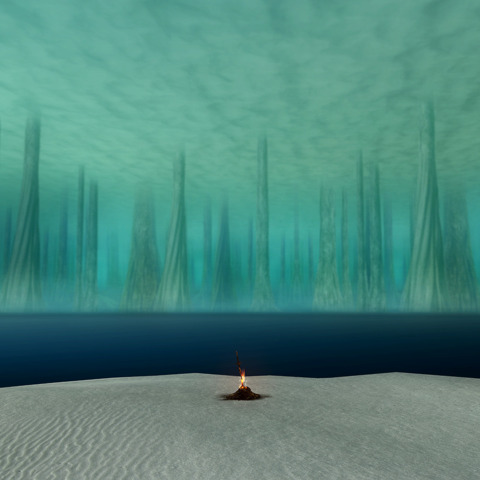

In [179]:
Image.open("ash-lake.png")

Maybe you're not sure which folder you're working in. Here's how we can check. I'm going to remove the output when I post these online, just because I don't want my file paths on the internet :)

In [181]:
os.getcwd() #current working directory

'C:\\Users\\lukea\\Documents\\GitHub\\Math9-Quarterly\\lectures'

This is how I can list everything in my current folder.

In [183]:
os.listdir()

['.ipynb_checkpoints',
 'ash-lake-crop.png',
 'ash-lake.png',
 'Ash_orange_blue.gif',
 'ash_red_dissolve.gif',
 'ash_red_scramble.gif',
 'ash_shine_flow.gif',
 'ash_thresholds.gif',
 'brightness_weird.gif',
 'cavelight.png',
 'chaosspiel iridescent.jpg',
 'diag_blend.png',
 'dryingtemple.png',
 'extra_art.ipynb',
 'FA24_lec23_24.ipynb',
 'images',
 'lec17_19.ipynb',
 'lec20_22.ipynb',
 'lec22_plotting.ipynb',
 'lec23_25.ipynb',
 'lec25_27.ipynb',
 'lec28_30.ipynb']

For organization, I almost always prefer to have a separate folder for images. I usually call it `images`.

In [185]:
os.listdir("images") #name of my folder

['.ipynb_checkpoints',
 '12.jpg',
 '13.jpg',
 '130942.png',
 '130943.png',
 '132766.png',
 '132767.png',
 '14.jpg',
 '15.jpg',
 '16.jpg',
 '17.jpg',
 '18.jpg',
 '19.jpg',
 '20.jpg',
 '21.jpg',
 '22.jpg',
 '23.jpg',
 '24.jpg',
 '25.jpg',
 '26.jpg',
 '27.jpg',
 'anor-londo.png',
 'b9db0815877977.5635a677be8bb.jpg',
 'Cloud.png',
 'magus.webp',
 'MW-place-Ghostgate.jpg',
 'record-of-lodoss-war-elwa1.webp',
 'Red_room.jpeg',
 'Sheogorath.jpg']

Say I wanted to open one of the images in my `images` folder. The following will cause an error, since the jpg is not in my current folder, but a subfolder.

In [187]:
Image.open('Red_room.jpeg')

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\lukea\\Documents\\GitHub\\Math9-Quarterly\\lectures\\Red_room.jpeg'

To navigate to the `images` folder, I could type out the path name directly, but this is going to be different for different operating systems. The way I'm going to show you is maybe cumbersome, but has the benefit of being able to work for any operating system.

In [189]:
s = os.path.join("images",'Red_room.jpeg')

In [191]:
s

'images\\Red_room.jpeg'

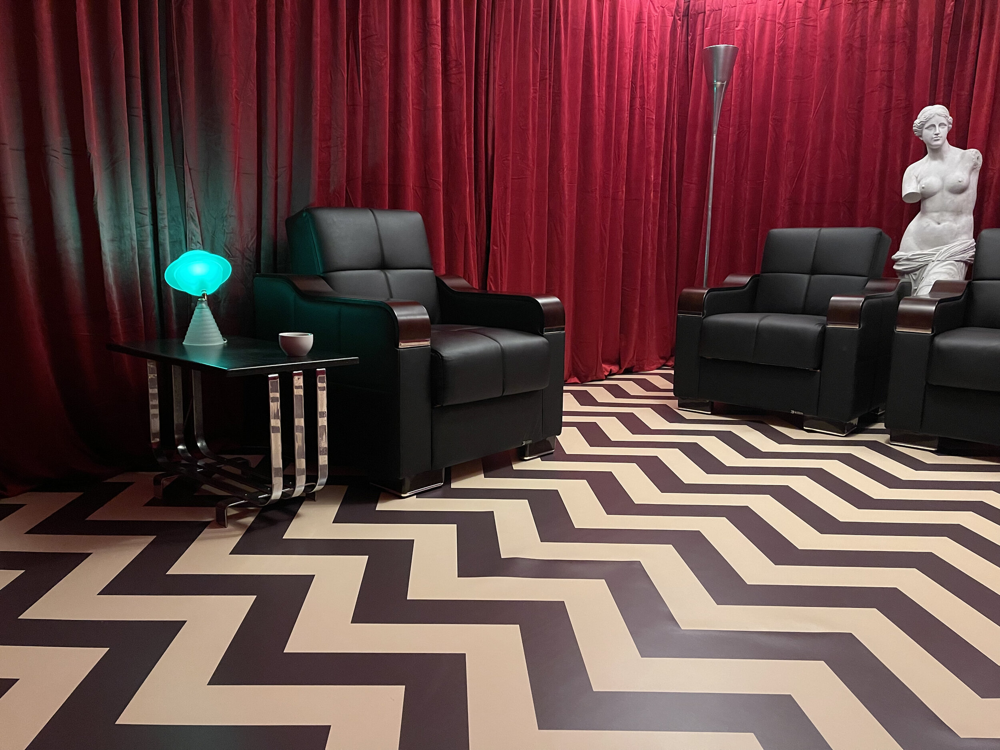

In [193]:
Image.open(s)

How could I get all of the jpgs in a folder?

In [55]:
os.listdir("images")

['.ipynb_checkpoints',
 '12.jpg',
 '13.jpg',
 '130942.png',
 '130943.png',
 '132766.png',
 '132767.png',
 '14.jpg',
 '15.jpg',
 '16.jpg',
 '17.jpg',
 '18.jpg',
 '19.jpg',
 '20.jpg',
 '21.jpg',
 '22.jpg',
 '23.jpg',
 '24.jpg',
 '25.jpg',
 '26.jpg',
 '27.jpg',
 'anor-londo.png',
 'b9db0815877977.5635a677be8bb.jpg',
 'Cloud.png',
 'magus.webp',
 'MW-place-Ghostgate.jpg',
 'record-of-lodoss-war-elwa1.webp',
 'Red_room.jpeg',
 'Sheogorath.jpg']

In [195]:
type(os.listdir("images"))

list

Less pythonic way:

In [197]:
[x for x in os.listdir("images") if x[-3:] == "jpg"]

['12.jpg',
 '13.jpg',
 '14.jpg',
 '15.jpg',
 '16.jpg',
 '17.jpg',
 '18.jpg',
 '19.jpg',
 '20.jpg',
 '21.jpg',
 '22.jpg',
 '23.jpg',
 '24.jpg',
 '25.jpg',
 '26.jpg',
 '27.jpg',
 'b9db0815877977.5635a677be8bb.jpg',
 'MW-place-Ghostgate.jpg',
 'Sheogorath.jpg']

More pythonic way:

In [200]:
[x for x in os.listdir("images") if x.endswith("png")]

['130942.png',
 '130943.png',
 '132766.png',
 '132767.png',
 'anor-londo.png',
 'Cloud.png']

In [202]:
[ x for x in os.listdir("images") if x.endswith("webp") ]

['magus.webp', 'record-of-lodoss-war-elwa1.webp']

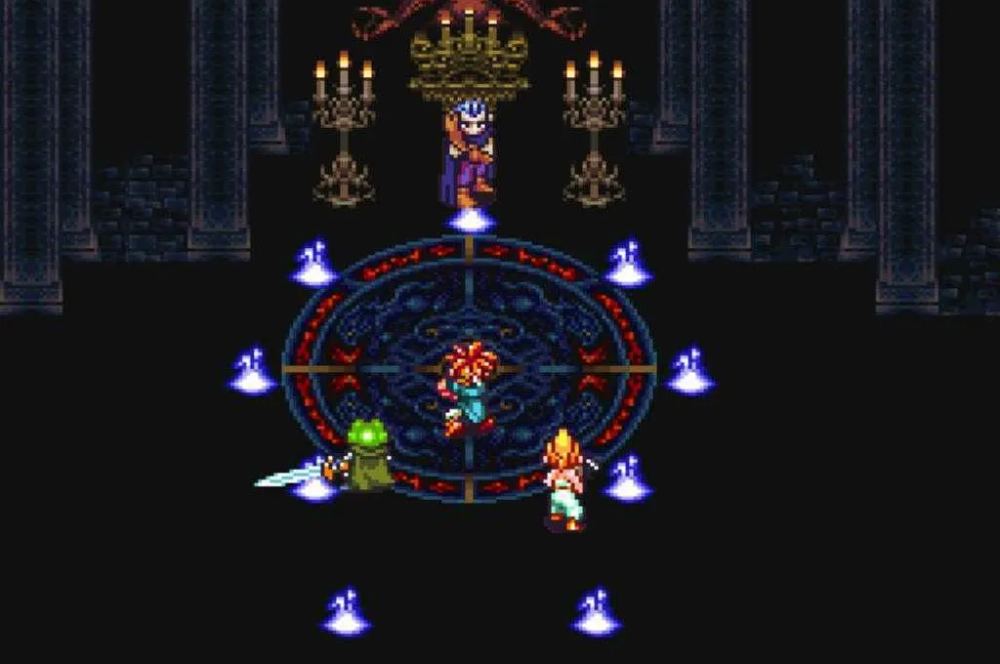

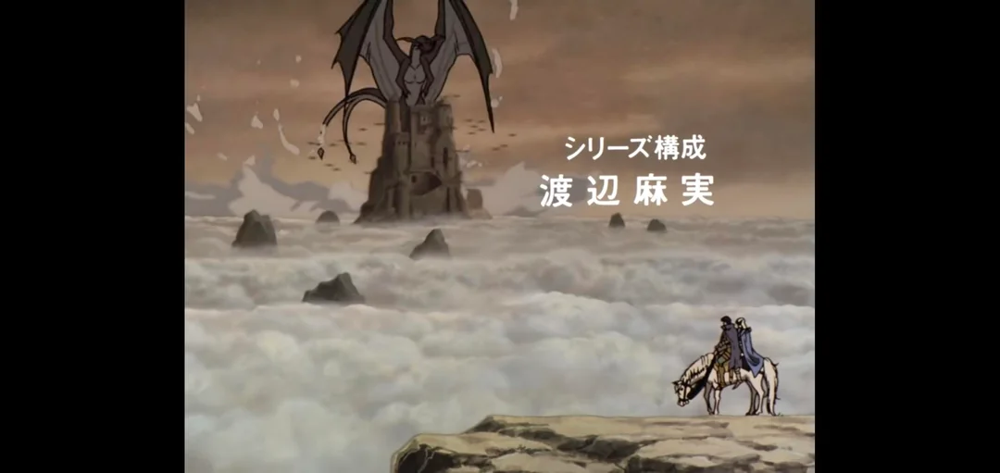

In [204]:
for x in os.listdir("images"):
    if x.endswith("webp"):
        img = Image.open(os.path.join("images",x))
        display(img)

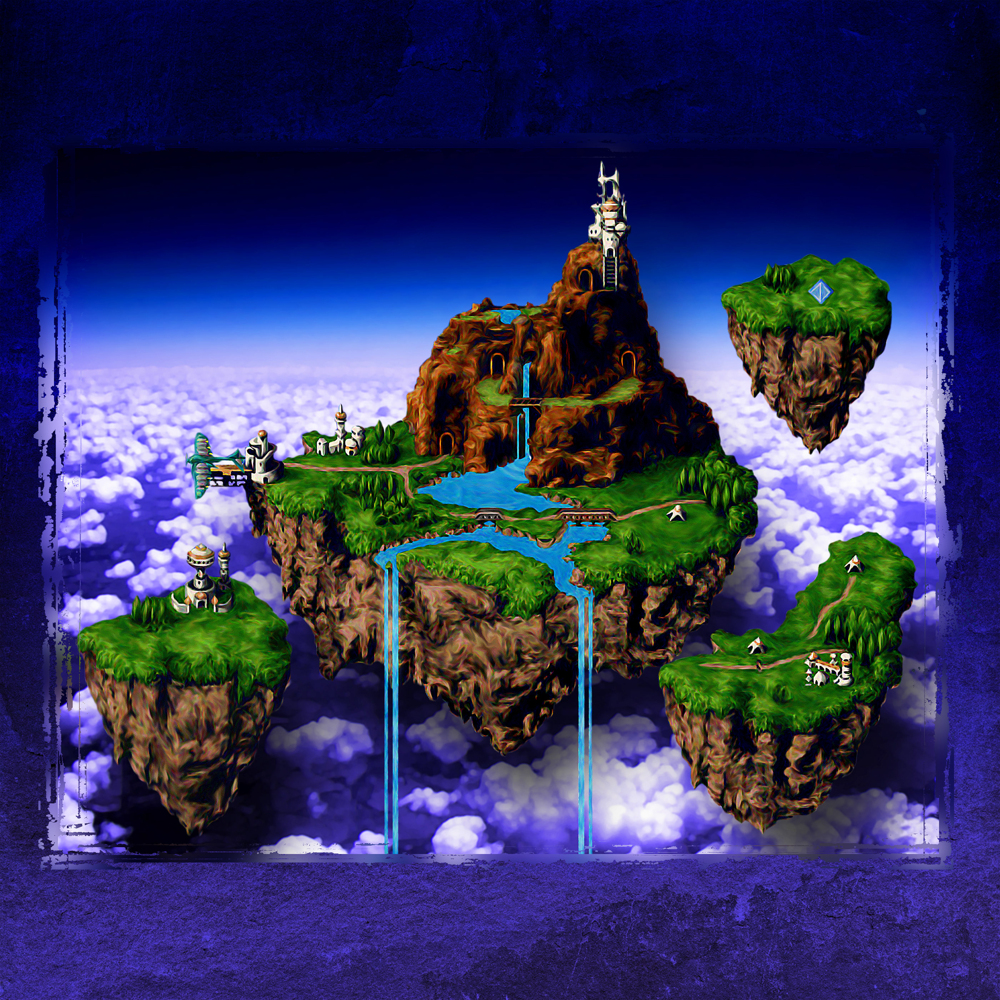

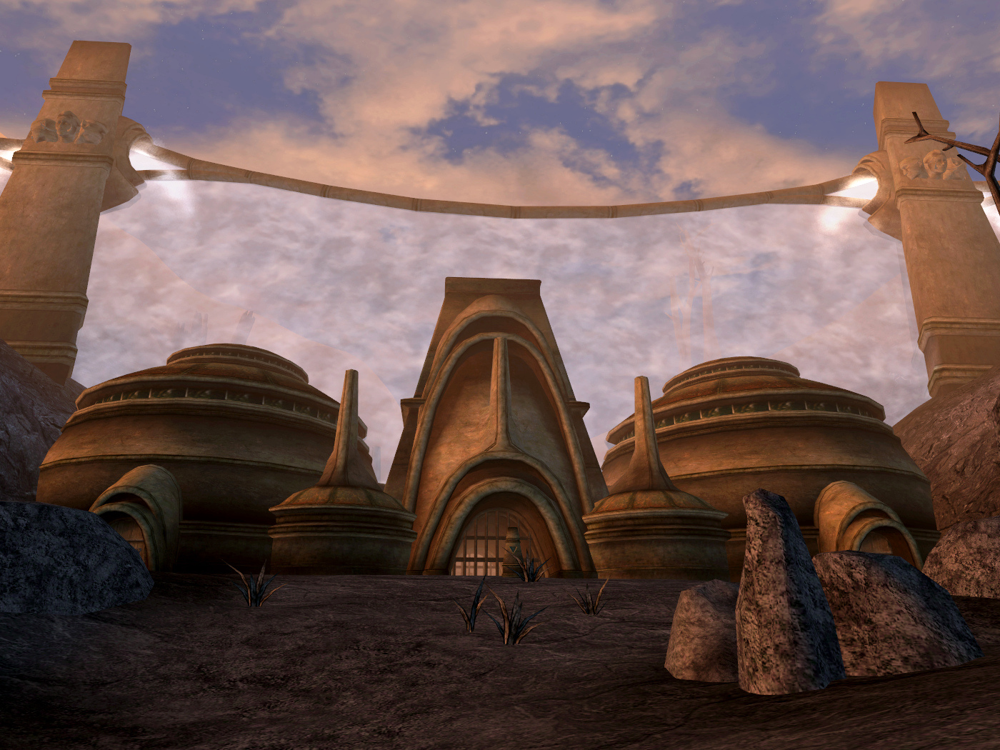

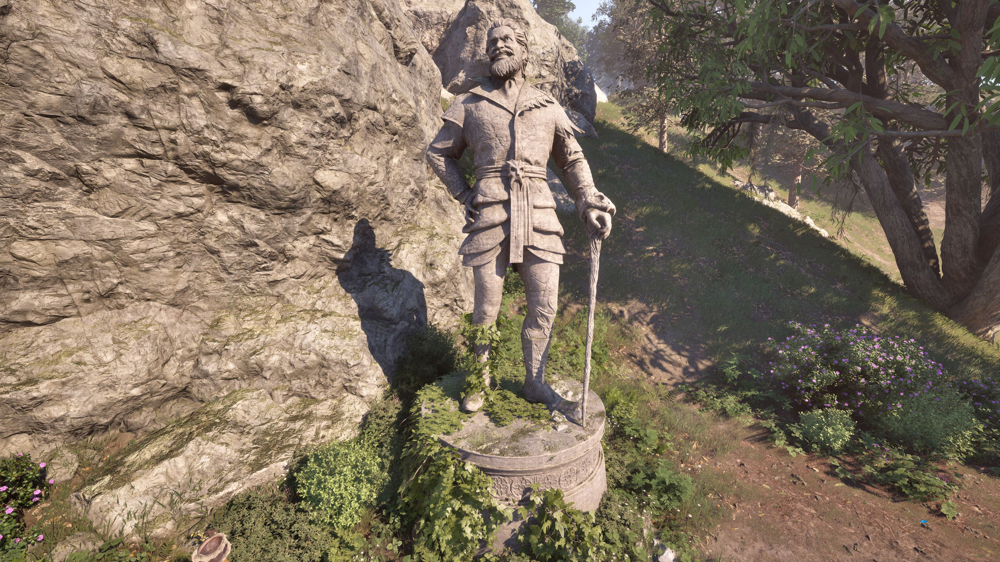

In [206]:
for x in os.listdir("images"):
    if x.endswith("jpg") and x[0].isalpha():
        img = Image.open(os.path.join("images",x))
        display(img)

### NumPy Arrays and Images

In [1]:
import numpy as np
from PIL import Image
import os

In [208]:
img = Image.open("ash-lake.png")

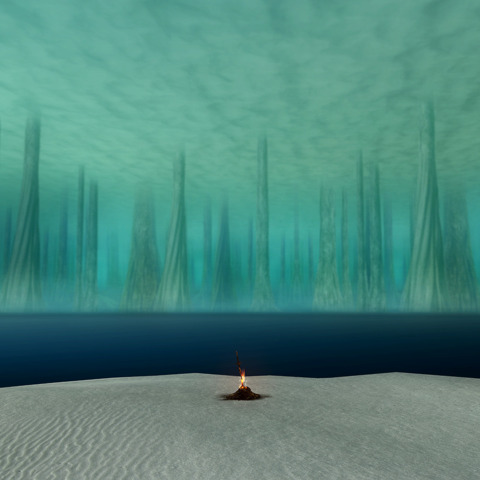

In [210]:
img

In [212]:
type(img)

PIL.PngImagePlugin.PngImageFile

We can see this is not a NumPy array...here's what we do.

In [214]:
arr = np.asarray(img)

In [216]:
arr

array([[[ 83, 161, 148],
        [ 83, 161, 148],
        [ 83, 161, 148],
        ...,
        [ 94, 157, 140],
        [ 94, 157, 140],
        [ 94, 157, 140]],

       [[ 83, 161, 148],
        [ 83, 161, 148],
        [ 83, 161, 148],
        ...,
        [ 93, 156, 139],
        [ 93, 156, 139],
        [ 93, 156, 139]],

       [[ 83, 161, 148],
        [ 83, 161, 148],
        [ 83, 161, 148],
        ...,
        [ 93, 156, 139],
        [ 92, 155, 138],
        [ 92, 155, 138]],

       ...,

       [[117, 128, 120],
        [140, 151, 143],
        [152, 163, 155],
        ...,
        [113, 126, 119],
        [117, 130, 123],
        [121, 134, 127]],

       [[128, 139, 131],
        [129, 140, 132],
        [124, 135, 127],
        ...,
        [112, 125, 118],
        [114, 127, 120],
        [116, 129, 122]],

       [[130, 141, 133],
        [118, 129, 121],
        [105, 117, 107],
        ...,
        [119, 132, 125],
        [120, 133, 126],
        [121, 134, 127]]

In [218]:
type(arr)

numpy.ndarray

In [220]:
arr.shape

(480, 480, 3)

Think of this as saying we have $480 \times 480$ pixels, and each pixel has an RGB (Red-Green-Blue) triplet.

Let's get the top-left-most pixel.

In [222]:
arr[0, 0]

array([ 83, 161, 148], dtype=uint8)

This says we have 83 Red, 161 Green, 148 Blue.

Maybe I wonder what the range of these RGB values is.

In [226]:
arr.min()

0

In [228]:
arr.max()

255

All together, there are $2^8 = 256$ possibilities for each RGB value. This is why we store these as 8-bit integers (notice the use of `dtype=uint8` in `arr`).

In [230]:
(arr[:,300:]).shape

(480, 180, 3)

Let's actually visualize this slice!

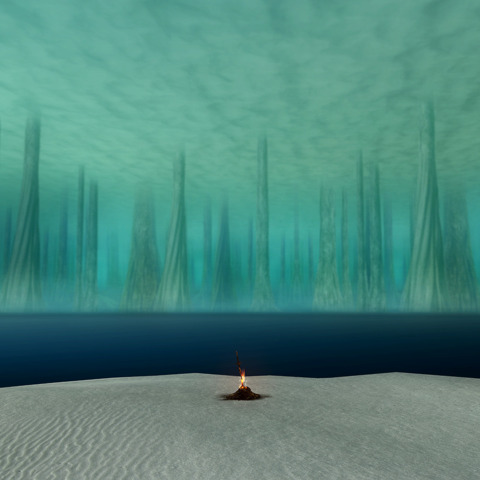

In [233]:
img

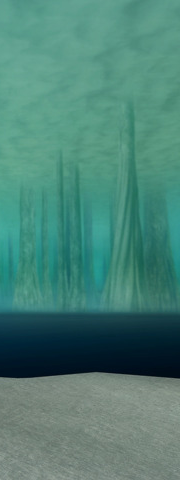

In [235]:
Image.fromarray(arr[:,300:])   #Sliced array gives cropped image

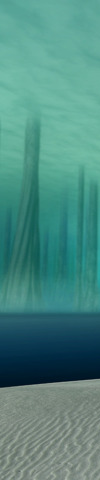

In [237]:
Image.fromarray(arr[:,:100])   #note that the [0,0] pixel is in the upper left corner

In [239]:
arr_3_slices = np.concatenate([arr[:,:50],arr[:,210:275], arr[:, -50:]], axis=1) #choose the axis where the array sizes are different.

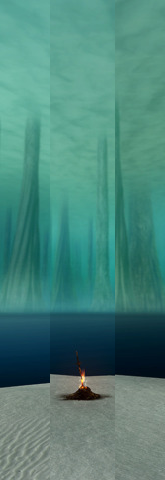

In [100]:
Image.fromarray(arr_3_slices)  #crop 3 times and combine them into one image

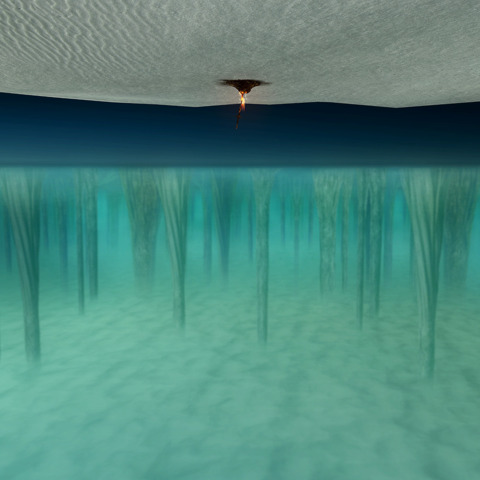

In [241]:
arr_flip = arr[::-1,:,:]
Image.fromarray(arr_flip)

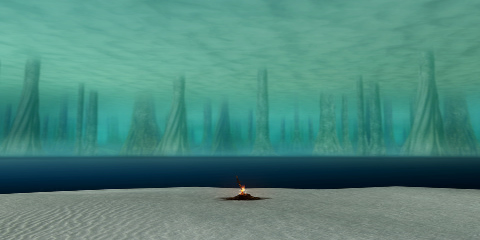

In [243]:
arr_squash = arr[::2,::,:]
Image.fromarray(arr_squash)

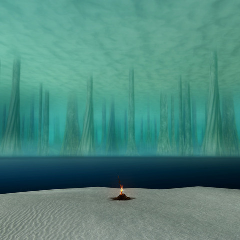

In [245]:
arr_shrink = arr[::2,::2,:]
Image.fromarray(arr_shrink)

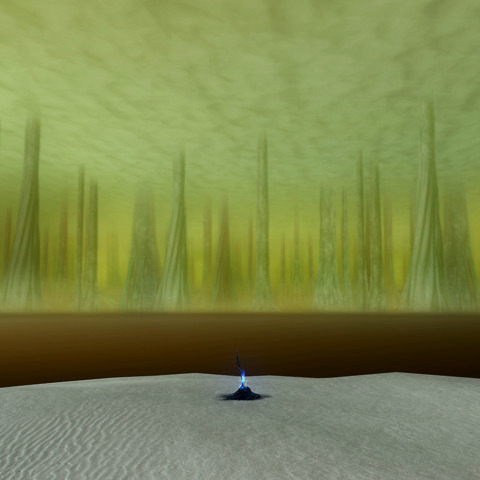

In [247]:
arr_colorswap = arr[:,:,::-1]
Image.fromarray(arr_colorswap)

images\Red_room.jpeg


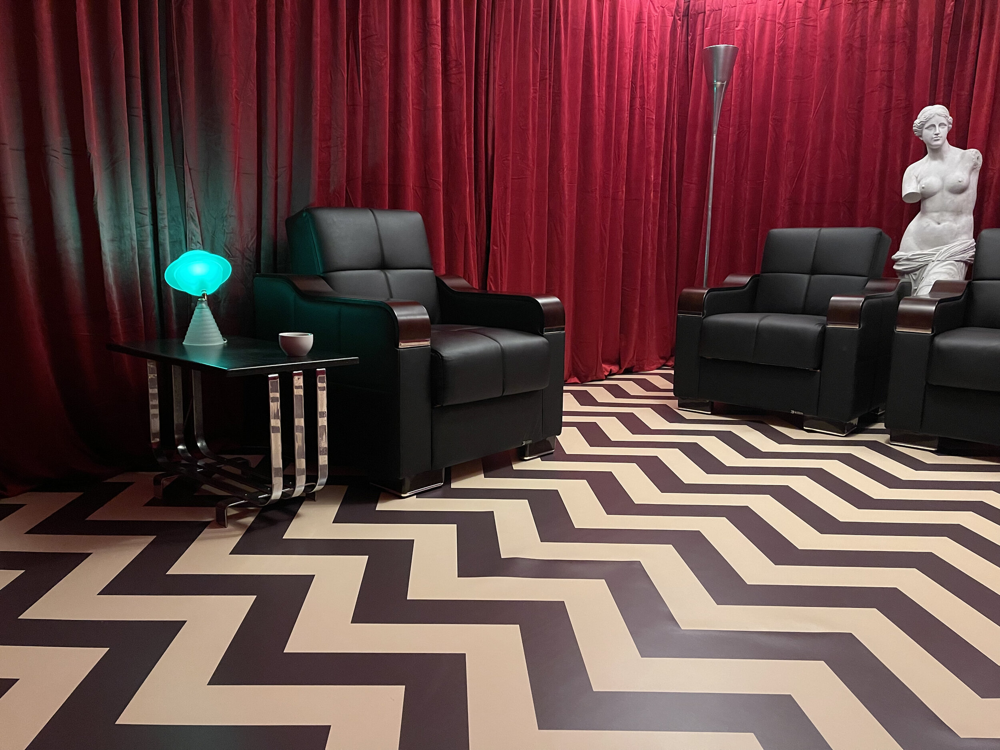

In [249]:
s = os.path.join("images",'Red_room.jpeg')
print(s)
Image.open(s)

### Blending Images

Goal: Crop the image of the lamp in the Red Room, and put it in Ash Lake.

In [251]:
arr_red = np.asarray(Image.open(s))
arr_red

array([[[ 80,  25,  31],
        [ 76,  21,  27],
        [ 70,  15,  21],
        ...,
        [148,  52,  63],
        [149,  53,  64],
        [146,  53,  63]],

       [[ 82,  27,  33],
        [ 81,  26,  32],
        [ 79,  24,  30],
        ...,
        [152,  56,  67],
        [152,  56,  67],
        [148,  55,  65]],

       [[ 75,  20,  26],
        [ 79,  24,  30],
        [ 81,  26,  32],
        ...,
        [153,  57,  68],
        [152,  56,  67],
        [146,  53,  63]],

       ...,

       [[175, 143, 122],
        [174, 142, 121],
        [174, 142, 121],
        ...,
        [115, 103, 107],
        [115, 103, 107],
        [115, 103, 107]],

       [[177, 145, 124],
        [175, 143, 122],
        [175, 143, 122],
        ...,
        [114, 102, 106],
        [114, 102, 106],
        [114, 102, 106]],

       [[179, 147, 126],
        [177, 145, 124],
        [176, 144, 123],
        ...,
        [116, 104, 108],
        [116, 104, 108],
        [116, 104, 108]]

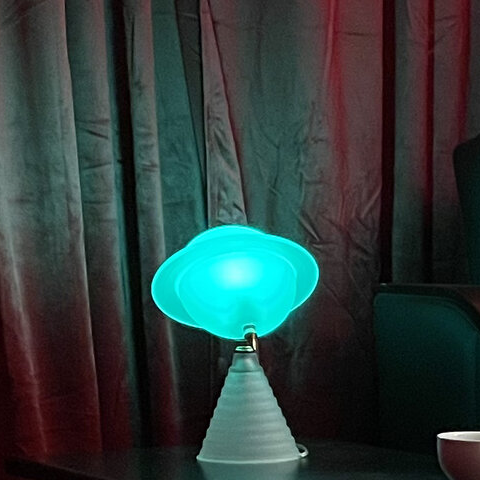

In [253]:
arr_r_crop = arr_red[400:880,260:740]
Image.fromarray(arr_r_crop)

In [255]:
arr_r_crop.shape  #same shape as Ash Lake

(480, 480, 3)

We can blend the two images by adding. Each color in each pixel is added together. We have to be careful because if a pixel's value goes over 255, or becomes negative, the colors start to look strange.

Technically, each color channel in each pixel is defined as an 8-bit integer (type `np.uint8`). This means the color's min is 0 and the max is 255. Any values that leave this range are modded so that they return to this range. However, this affects the colors in a major way. 

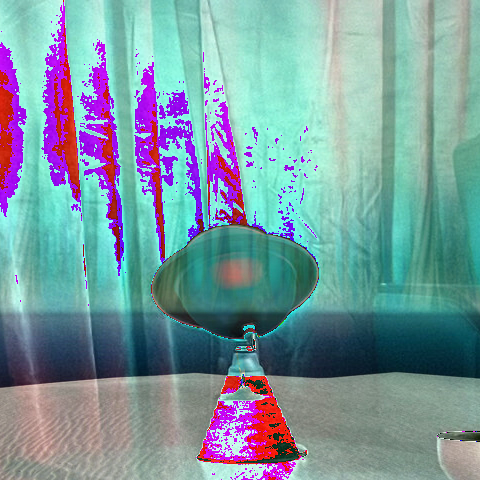

In [258]:
Image.fromarray(arr + arr_r_crop)

It's better to take a weighted average of the arrays, to blend images together. This prevents overflow.

Make sure values are integers, PIL is somewhat picky. We must cast our final numbers back to `np.uint8` to avoid decimals in final calculation. Some rounding will occur.

In [260]:
weighted_average = lambda weight, arr1, arr2: np.uint8((1-weight)*arr1 + weight*arr2)

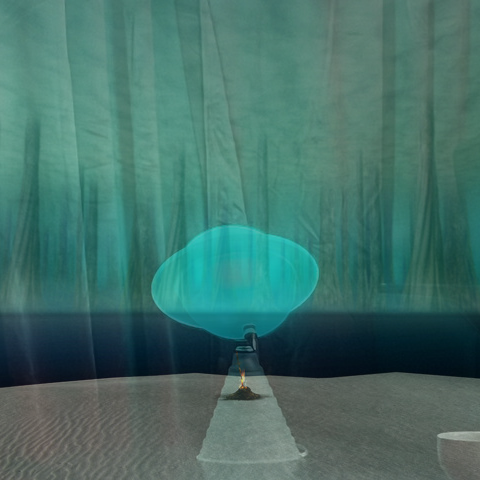

In [268]:
weight=0.3
Image.fromarray(weighted_average(weight, arr, arr_r_crop))

We can also scale this image so that the lamp better matches the bonfire. If we want to scale by 1/2, then the trick is to take every other pixel when we crop.

(480, 215, 3)


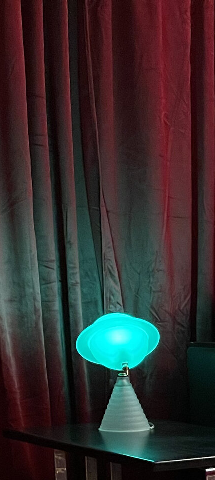

In [270]:
r_crop_scale = arr_red[:960:2,260:690:2]
print(r_crop_scale.shape)
Image.fromarray(r_crop_scale)

We will apply our `weighted_average` function to a slice of the image array, rather than the entire array. This will place our cropped and scaled red room image over the bonfire.

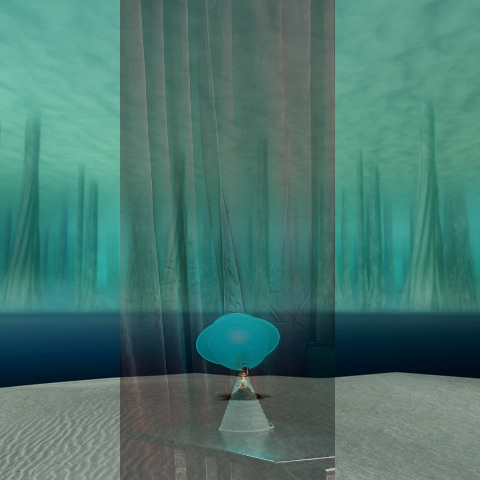

In [284]:
arr_sc = arr.copy()
weight = 0.4
arr_sc[:, 120:335] = weighted_average(weight, arr_sc[:, 120:335], r_crop_scale)
Image.fromarray(arr_sc)

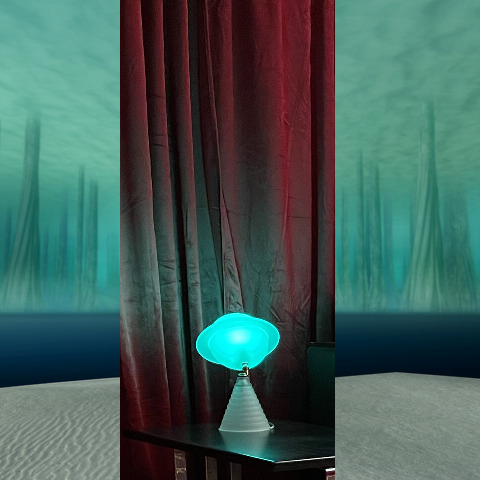

In [317]:
weight = 1
arr_sc[:, 120:335] = weighted_average(weight, arr_sc[:, 120:335], r_crop_scale)
Image.fromarray(arr_sc)

Now what if we want to blend the curtains in a fancier way? Let's get another crop with more background.

(480, 480, 3)


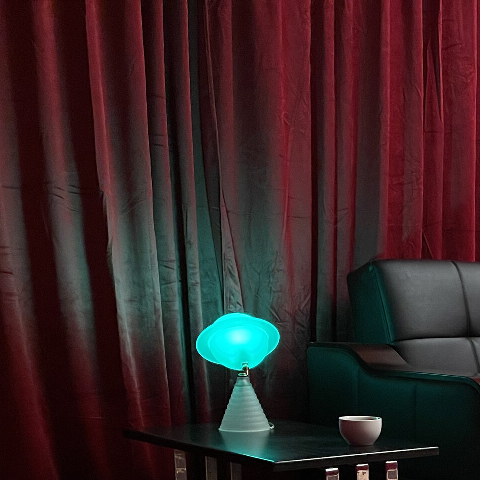

In [286]:
r_crop_scale_2 = arr_red[:960:2,20:980:2]
print(r_crop_scale_2.shape)
Image.fromarray(r_crop_scale_2)

Here, instead of a constant weight, we will take weights that increase from 0 to 0.8 as we travel from left to right.

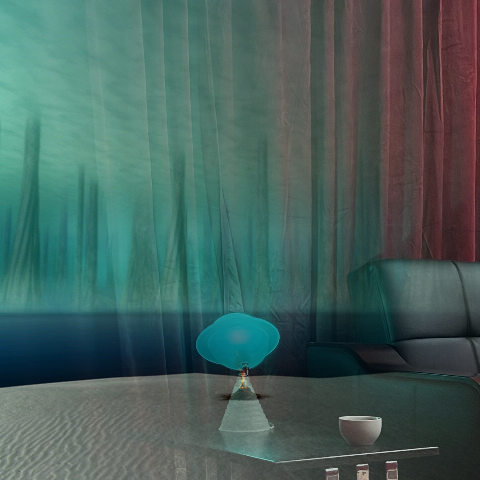

In [288]:
x = np.linspace(0,0.8,480) #480 weights, evenly spaced from 0 to 0.8. Use this for a row of the weights tensor.
x = x.reshape(1,-1, 1) #match the 3-dim tensor structure of our image, using 1 row, 480 columns, and 1 depth.
weights = np.zeros_like(arr, dtype = np.float64)
weights[:,:,:] = x #broadcast x across all rows of our weights tensor.
Image.fromarray(weighted_average(weights, arr, r_crop_scale_2))

Now let's do this vertically.

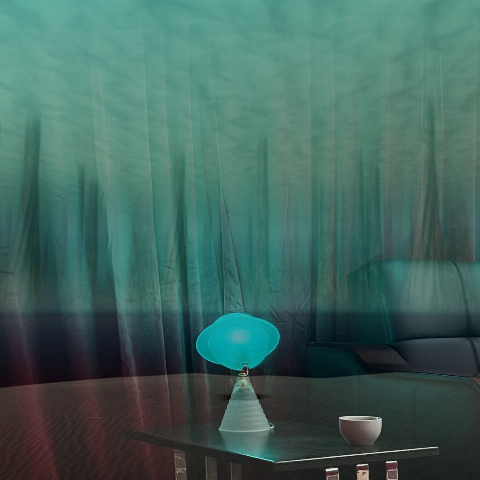

In [293]:
x = np.linspace(0,0.8,480)
x = x.reshape(-1,1, 1) #The only difference between this code cell and the previous code cell is the placement of -1.
weights = np.zeros_like(arr, dtype = np.float64)
weights[:,:,:] = x 
Image.fromarray(weighted_average(weights, arr, r_crop_scale_2) )

We can create a diagonal blend with by broadcasting a vertical array with a horizontal array

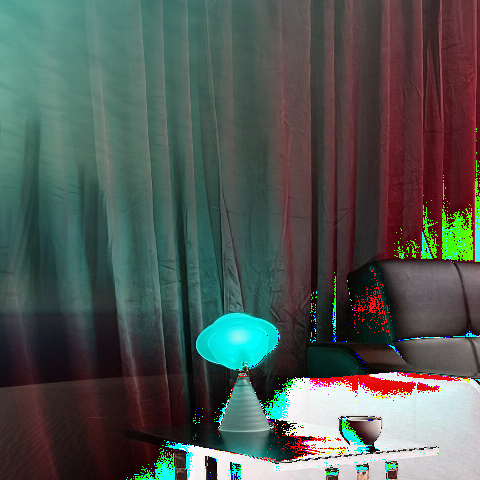

In [297]:
x = np.linspace(0,0.8,480)
xh = x.reshape(1,-1, 1)
xv = x.reshape(-1,1, 1)
x_diag = xh + xv
weights = np.zeros_like(arr, dtype = np.float64)
weights[:,:,:] = x_diag
diag_img = Image.fromarray(weighted_average(weights, arr, r_crop_scale_2)) 
diag_img

You can save images as files. You just need to save the image as a variable first.

In [300]:
diag_img.save("diag_blend.png") #can save any image we like with this method. we can also use f-strings.

Note that when we take `xh + xv`, the maximum is now 1.6 rather than 0.8. We will adjust `x` to compensate for this

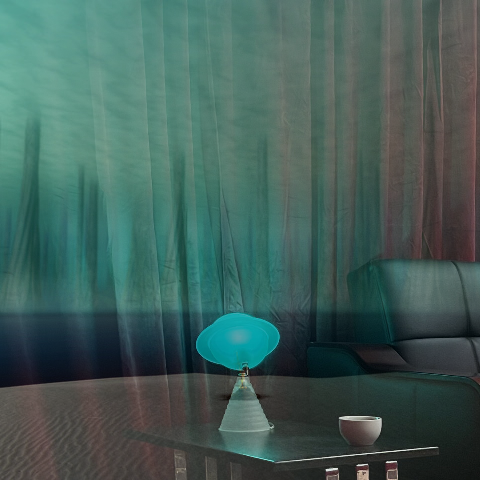

In [302]:
x = np.linspace(0,0.45,480) #smaller maximum to prevent overflow
xh = x.reshape(1,-1, 1)
xv = x.reshape(-1,1, 1)
x_diag = xh + xv
weights = np.zeros_like(arr, dtype = np.float64)
weights[:,:,:] = x_diag
Image.fromarray(weighted_average(weights, arr, r_crop_scale_2))

One more blend: The Dissolve Blend. Each pixel is randomly taken from one array or the other.

In [304]:
rng = np.random.default_rng()
l = np.array([0,1], dtype=np.uint8) #must convert [0,1] to 8-bit integers
w = 0.7 #weight for how much the first image will be represented
dis_rng = rng.choice(l, size=(480,480,1), p=[w, 1-w]) #rng.choice lets you choose the probabilities for each choice!
print(dis_rng)
arr_dis = arr*dis_rng  #the 1's in dis_rng determine which pixels in Ash Lake are kept.
r_dis = (1-dis_rng)*r_crop_scale_2 #the 0's in dis_rng become 1's in 1-dis_rng, and therefore the opposite pixels from The Red Room are kept.

[[[0]
  [0]
  [0]
  ...
  [0]
  [0]
  [0]]

 [[1]
  [0]
  [0]
  ...
  [0]
  [0]
  [1]]

 [[0]
  [1]
  [0]
  ...
  [1]
  [0]
  [1]]

 ...

 [[0]
  [0]
  [1]
  ...
  [1]
  [0]
  [0]]

 [[1]
  [0]
  [0]
  ...
  [0]
  [0]
  [1]]

 [[0]
  [0]
  [0]
  ...
  [1]
  [1]
  [0]]]


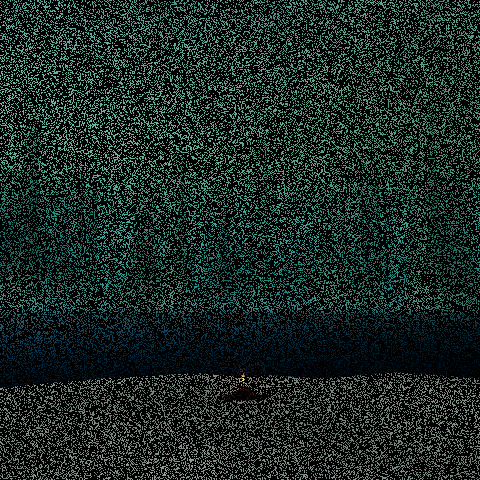

In [306]:
Image.fromarray(arr_dis)

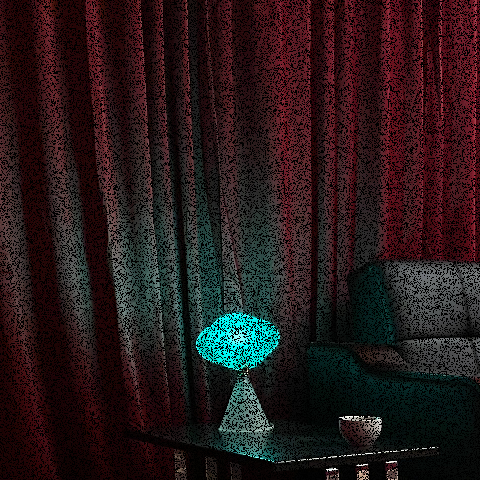

In [308]:
Image.fromarray(r_dis)

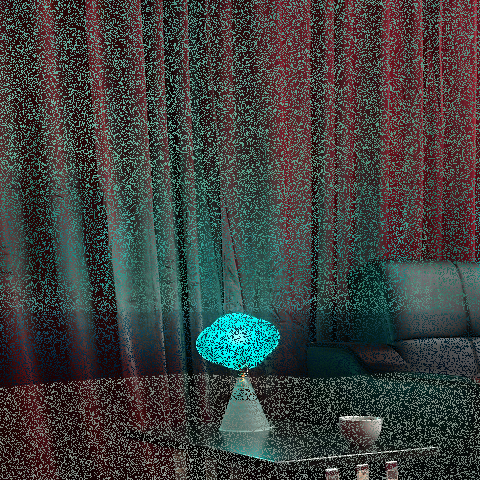

In [310]:
Image.fromarray(arr_dis + r_dis)

A dissolve is less impressive on its own, but a gradual dissolve makes for a good animation. It takes just a little more work.

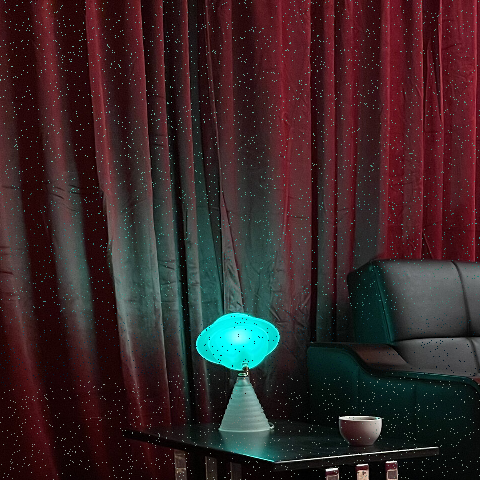

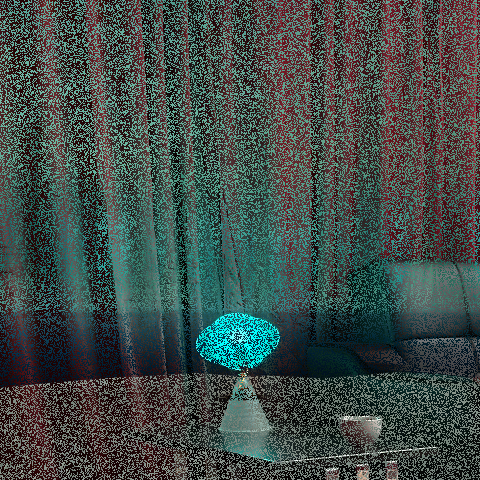

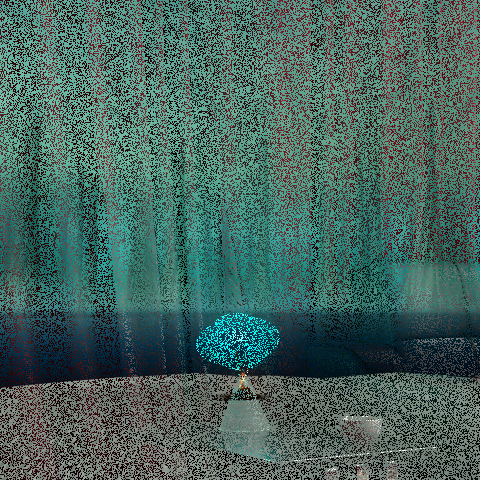

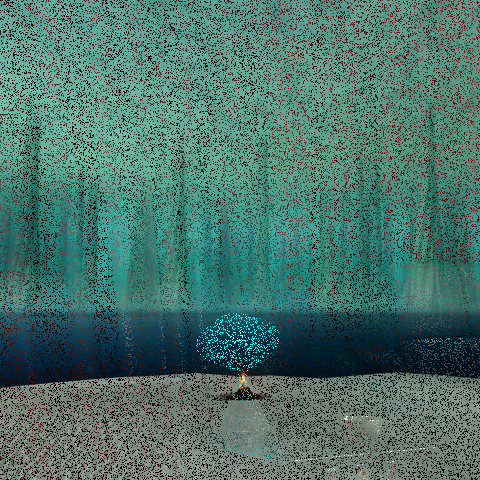

In [319]:
l = np.array([0,1], dtype=np.uint8) 
w = 0.98 #very heavily weighted towards 1st image
keep = np.zeros((480,480,1), dtype=np.uint8) #start by keeping pixels from the red room. Gradually replace them with Ash lake by flipping 0's to 1's.
anim_frames = []
steps = 100
for n in range(steps):
    dis_rng = rng.choice(l, size=(480,480,1), p=[w, 1-w])
    keep = np.maximum(keep, dis_rng)  #note that np.maximum compares 2 arrays elementwise, while np.max is a comparison within 1 array
    arr_keep = arr*keep  #the 1's in keep determine which pixels in Ash Lake are kept.
    r_keep = (1-keep)*r_crop_scale_2
    img_frame = Image.fromarray(arr_keep+r_keep)
    if n%25 == 0:
        display(img_frame) #display every 25th frame, just to prevent output clutter
    anim_frames.append(img_frame)

anim_frames = anim_frames + anim_frames[-1::-1] #trick to make the animation return to the beginning

In [106]:
def save_anim(anim_frames,filename, dur=100): #must include .gif extension in filename
    anim_frames[0].save(
            filename,
            save_all=True,
            append_images=anim_frames[1:],  # Append the rest of the frames
            duration=dur,              # Duration of each frame in milliseconds
            loop=0                     # 0 means loop indefinitely
        )

In [559]:
save_anim(anim_frames,"ash_red_dissolve.gif")

Note that if we don't take that extra step with `keep`, our image is not a fade.

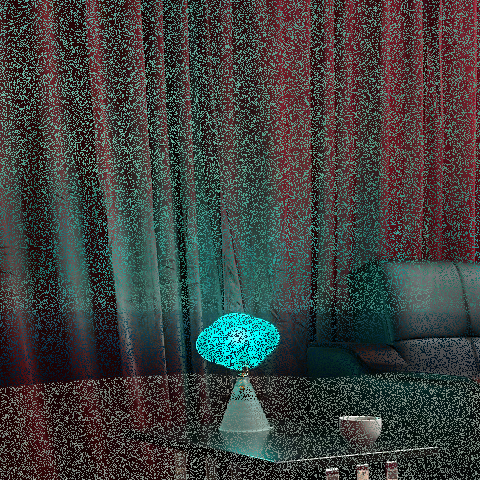

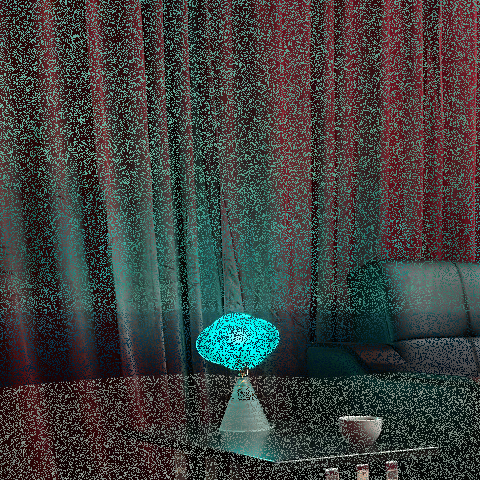

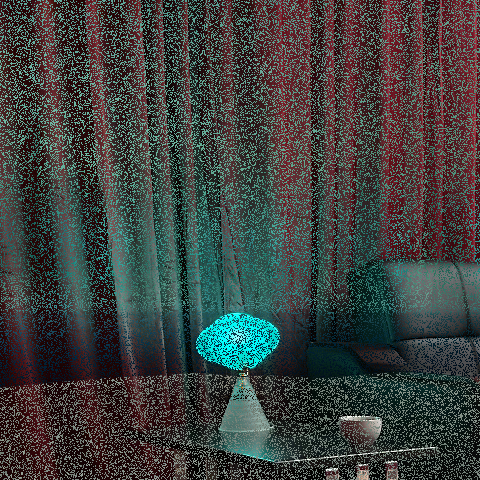

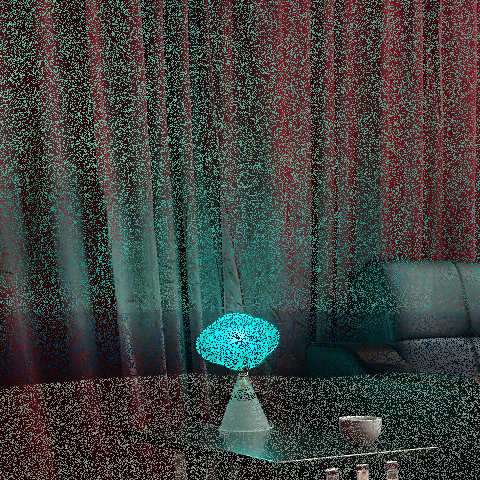

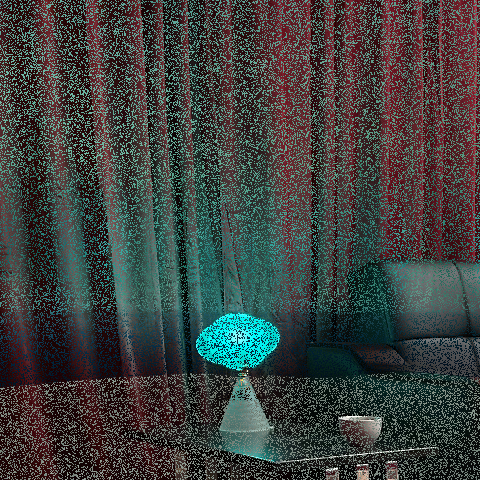

In [108]:
l = np.array([0,1], dtype=np.uint8) 
w = 0.70 #heavily weighted towards 1st image
anim_frames = []
steps = 30
for n in range(steps):
    dis_rng = rng.choice(l, size=(480,480,1), p=[w, 1-w])
    arr_dis = arr*dis_rng  #the 1's in keep determine which pixels in Ash Lake are kept.
    r_dis = (1-dis_rng)*r_crop_scale_2
    img_frame = Image.fromarray(arr_dis+r_dis)
    if n%6 == 0:
        display(img_frame)
    anim_frames.append(img_frame)

In [565]:
save_anim(anim_frames,'ash_red_scramble.gif')

### A note on organization

When you create lots of custom functions, and import lots of packages, it's a smart idea to put each of those functions and packages into one cell. This way, you don't have to remember what cell a function was in. :)

In [1]:
import numpy as np
import os
from PIL import Image

img = Image.open("ash-lake.png")
arr = np.asarray(img)
s = os.path.join("images",'Red_room.jpeg')
arr_red = np.asarray(Image.open(s))
r_crop_scale_2 = arr_red[:960:2,20:980:2]

def save_anim(anim_frames,filename, dur=100): #must include .gif extension in filename
    anim_frames[0].save(
            filename,
            save_all=True,
            append_images=anim_frames[1:],  # Append the rest of the frames
            duration=dur,              # Duration of each frame in milliseconds
            loop=0                     # 0 means loop indefinitely
        )

weighted_average = lambda weight, arr1, arr2: np.uint8((1-weight)*arr1 + weight*arr2)

### Averaging images in 2D video game graphics: Transparent water

More modern graphics rendering and photo software expand the formatting of pictures from a (#rows, #columns, 3) (Red, Green, Blue) tensor to a (#rows, #columns, 4) (Red, Green, Blue, Alpha) tensor. The Alpha = 255 means that a pixel is completely opaque, while decreasing Alpha makes that pixel more and more transparent, until  Alpha = 0 gives a totally invisible pixel.

However, the graphics in popular early game consoles (Super Nintendo, Sega Genesis, etc.) were not designed using an Alpha value that could be manipulated. Yet transparent graphical effects were definitely present. How did they manage this with only a (Red, Green, Blue) image?

images\130943.png


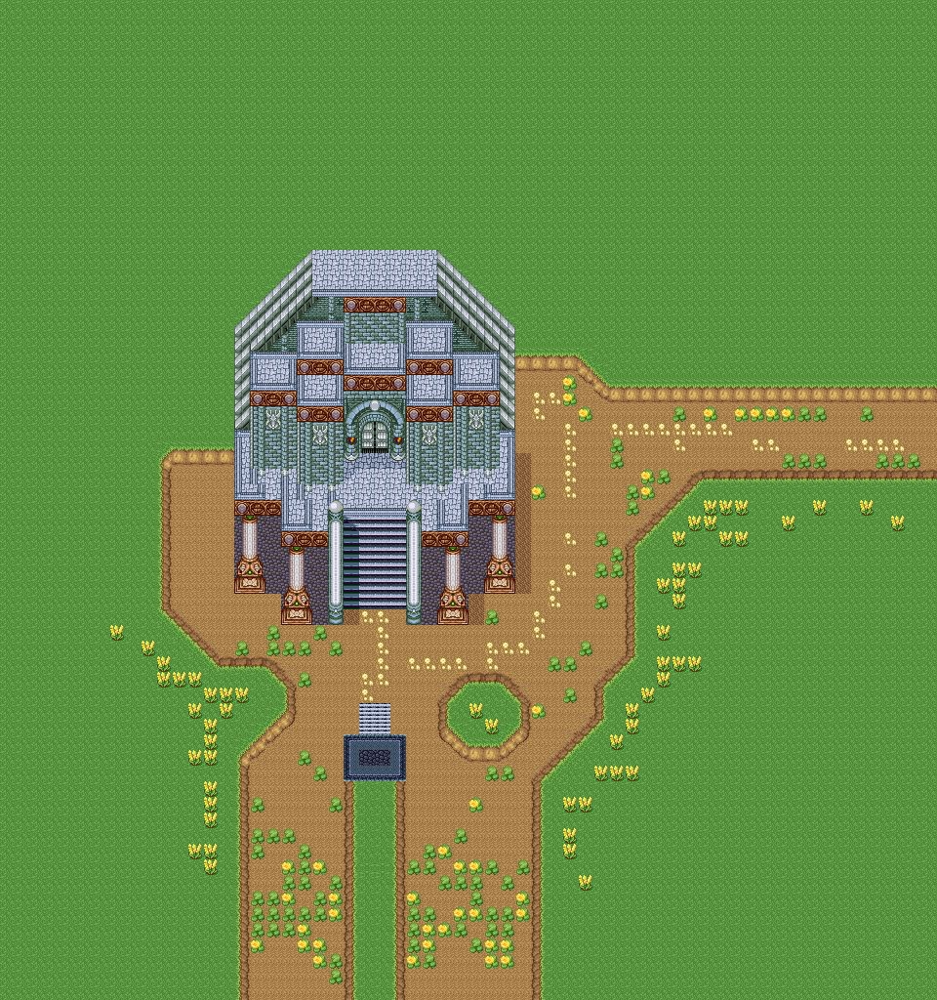

In [3]:
s1 = os.path.join("images",'130943.png')  #Water Temple
print(s1)
Image.open(s1)

images\130942.png


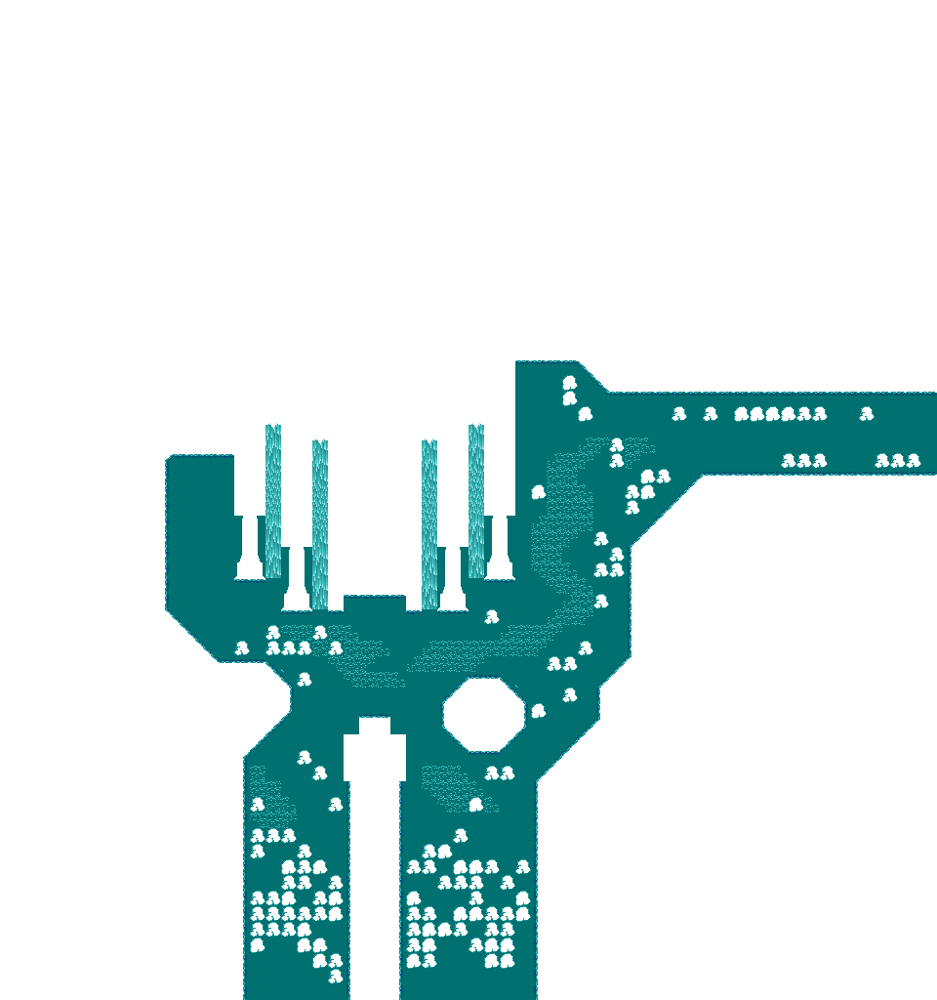

In [5]:
s2 = os.path.join("images",'130942.png') #The water in the water temple
print(s2)
Image.open(s2)

In practice, the parts of the picture that appear transparent or clear above are actually stored in-game as a different color altogether. Often a  bright hot pink or bright lime green are used, so that the game later knows to ignore this color (think of how movies with CG are green screened).

Averaging two arrays together will be close to the proper transparency effect, but not quite correct.

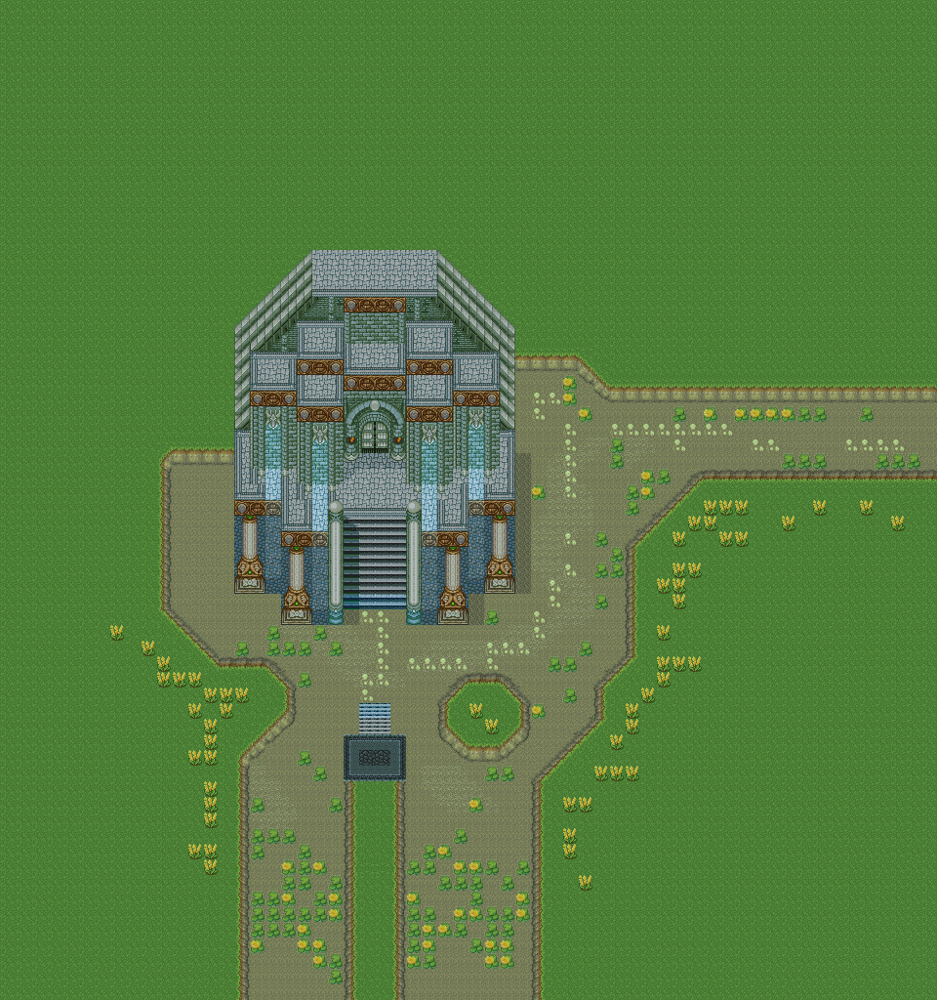

In [8]:
arr_temple = np.asarray(Image.open(s1))
arr_watermap = np.asarray(Image.open(s2))
Image.fromarray(weighted_average(0.3, arr_temple, arr_watermap))

The actual transparency effect works, but averaging the entire image causes the non-water parts of the image to darken.

In [11]:
arr_watermap #The "Transparent" pixels are actually stored as a dark green, for some reason. [48, 80, 32]

array([[[48, 80, 32],
        [48, 80, 32],
        [48, 80, 32],
        ...,
        [48, 80, 32],
        [48, 80, 32],
        [48, 80, 32]],

       [[48, 80, 32],
        [48, 80, 32],
        [48, 80, 32],
        ...,
        [48, 80, 32],
        [48, 80, 32],
        [48, 80, 32]],

       [[48, 80, 32],
        [48, 80, 32],
        [48, 80, 32],
        ...,
        [48, 80, 32],
        [48, 80, 32],
        [48, 80, 32]],

       ...,

       [[48, 80, 32],
        [48, 80, 32],
        [48, 80, 32],
        ...,
        [48, 80, 32],
        [48, 80, 32],
        [48, 80, 32]],

       [[48, 80, 32],
        [48, 80, 32],
        [48, 80, 32],
        ...,
        [48, 80, 32],
        [48, 80, 32],
        [48, 80, 32]],

       [[48, 80, 32],
        [48, 80, 32],
        [48, 80, 32],
        ...,
        [48, 80, 32],
        [48, 80, 32],
        [48, 80, 32]]], dtype=uint8)

In [13]:
bool = arr_watermap == [48, 80, 32]   #Find all the places where the dark green color is present in the watermap
bool

array([[[ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True],
        ...,
        [ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True]],

       [[ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True],
        ...,
        [ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True]],

       [[ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True],
        ...,
        [ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True]],

       ...,

       [[ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True],
        ...,
        [ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True]],

       [[ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True],
        ...,
        [ True,  True,  True],
        [ True,  True,  True],
        [ True,

In [15]:
arr_watermap_2 = arr_watermap.copy()   #Take a copy of the original watermap

In [17]:
arr_watermap_2[bool] = arr_temple[bool]  #Any pixel with the dark green in the watermap is replaced with the Temple background.

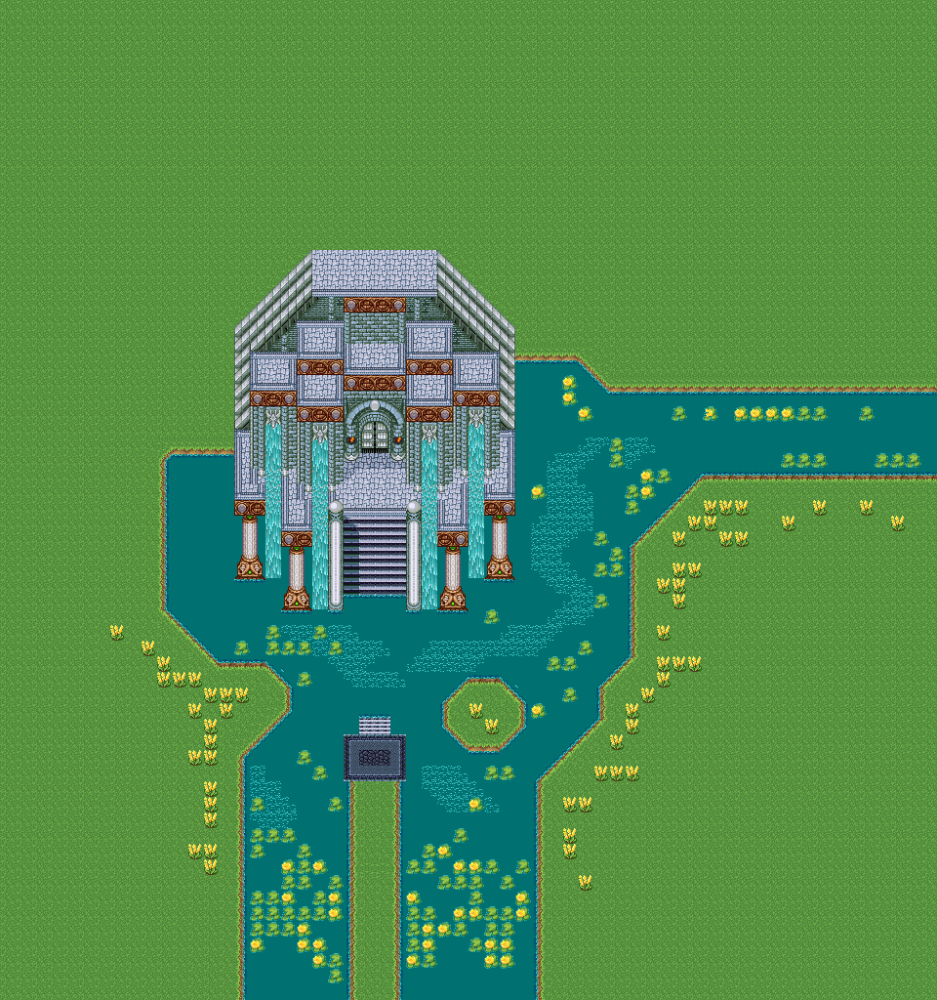

In [19]:
Image.fromarray(arr_watermap_2) #Now the watermap has the background image. There's no transparency, but we're one step away!

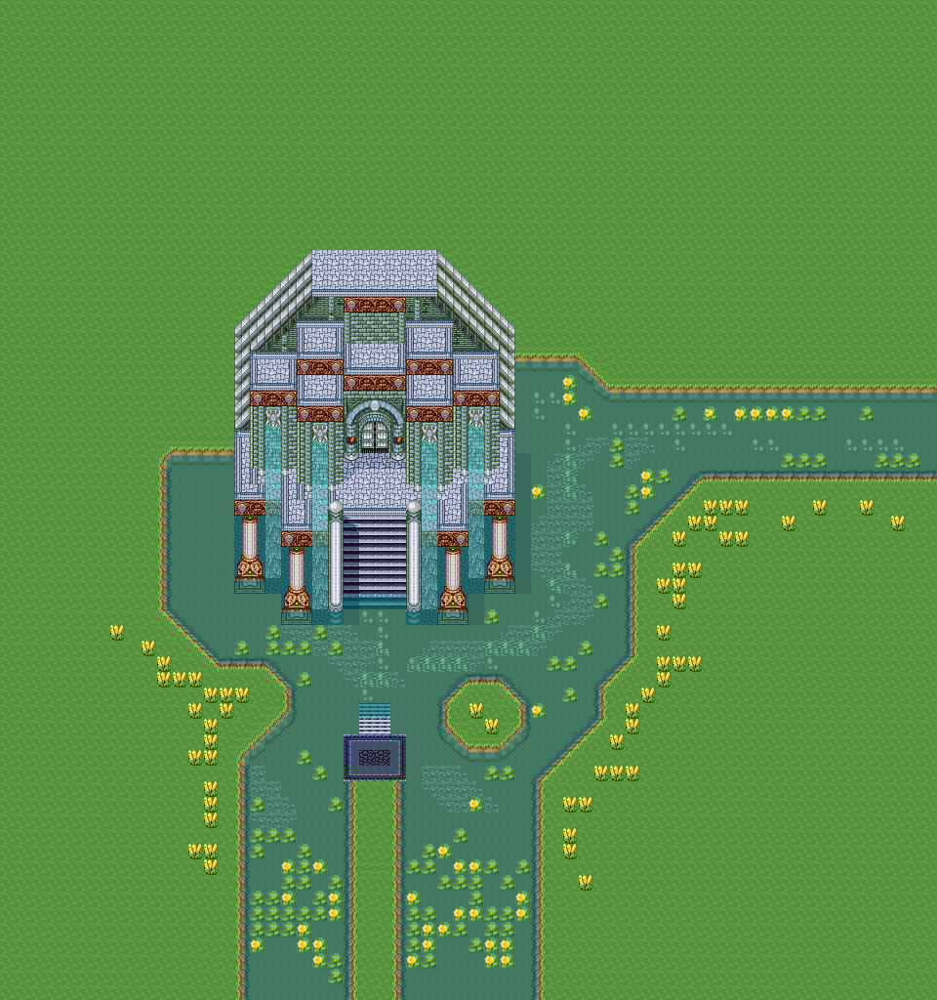

In [21]:
Image.fromarray(weighted_average(0.6, arr_temple, arr_watermap_2))

Let's combine all of the steps into one function, and try this process again in a few other cases.

In [46]:
def transparent_layer(weight, mask_color, arr_bg, arr_transp):
    bool = arr_transp == mask_color  #mask will be the color we replace
    arr_transp2 = arr_transp.copy()
    arr_transp2[bool] = arr_bg[bool]
    arr_averaged = weighted_average(weight, arr_bg, arr_transp2)
    return arr_averaged

Original image, but now the water is more transparent further from the temple. Gives the effect that the water is drying up.

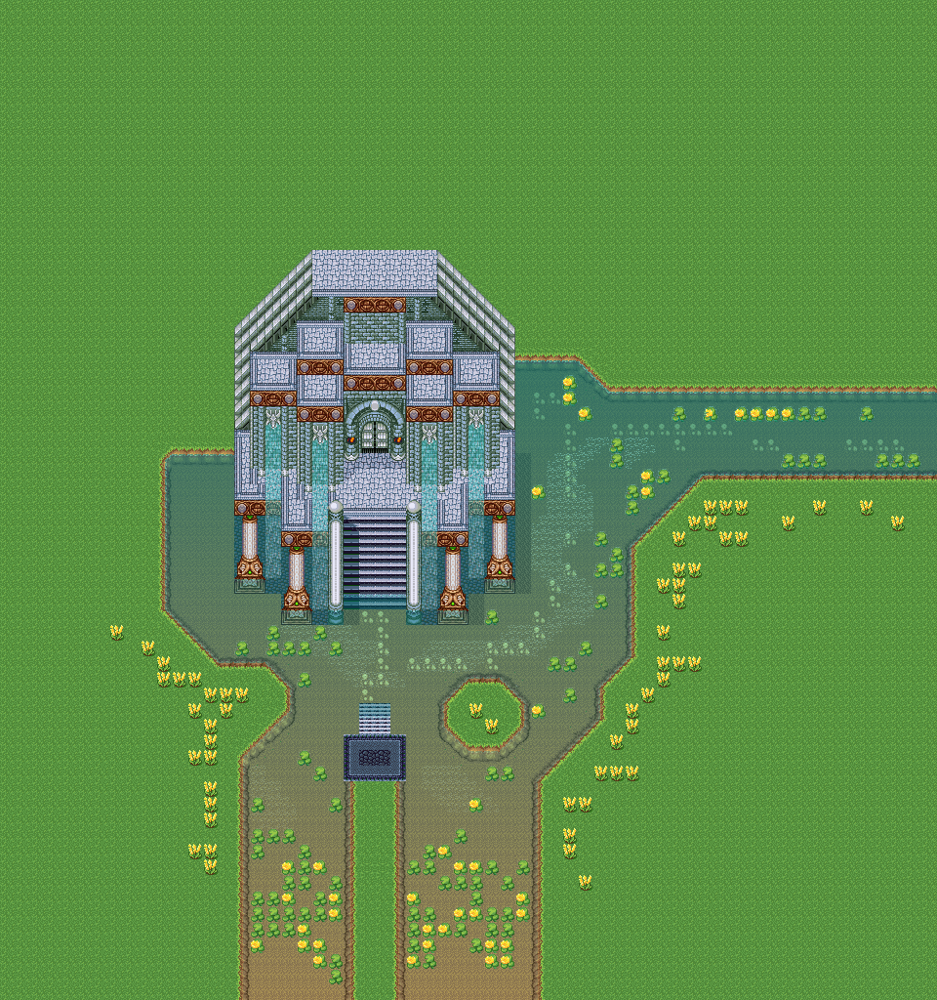

In [44]:
pic_height = arr_temple.shape[0]
x = np.linspace(1,0.1,pic_height) 
x = x.reshape(-1,1, 1)
weights = np.zeros_like(arr_temple, dtype = np.float64)
weights[:,:,:] = x 

mask = [48, 80, 32]

arr_water_temple = transparent_layer(weights, mask, arr_temple, arr_watermap)
img_water_temple = Image.fromarray(arr_water_temple)
img_water_temple

In [37]:
arr

array([[[ 83, 161, 148],
        [ 83, 161, 148],
        [ 83, 161, 148],
        ...,
        [ 94, 157, 140],
        [ 94, 157, 140],
        [ 94, 157, 140]],

       [[ 83, 161, 148],
        [ 83, 161, 148],
        [ 83, 161, 148],
        ...,
        [ 93, 156, 139],
        [ 93, 156, 139],
        [ 93, 156, 139]],

       [[ 83, 161, 148],
        [ 83, 161, 148],
        [ 83, 161, 148],
        ...,
        [ 93, 156, 139],
        [ 92, 155, 138],
        [ 92, 155, 138]],

       ...,

       [[117, 128, 120],
        [140, 151, 143],
        [152, 163, 155],
        ...,
        [113, 126, 119],
        [117, 130, 123],
        [121, 134, 127]],

       [[128, 139, 131],
        [129, 140, 132],
        [124, 135, 127],
        ...,
        [112, 125, 118],
        [114, 127, 120],
        [116, 129, 122]],

       [[130, 141, 133],
        [118, 129, 121],
        [105, 117, 107],
        ...,
        [119, 132, 125],
        [120, 133, 126],
        [121, 134, 127]]

In [39]:
arr_water_temple

array([[[ 83, 161, 148],
        [ 83, 161, 148],
        [ 83, 161, 148],
        ...,
        [ 94, 157, 140],
        [ 94, 157, 140],
        [ 94, 157, 140]],

       [[ 83, 161, 148],
        [ 83, 161, 148],
        [ 83, 161, 148],
        ...,
        [ 93, 156, 139],
        [ 93, 156, 139],
        [ 93, 156, 139]],

       [[ 83, 161, 148],
        [ 83, 161, 148],
        [ 83, 161, 148],
        ...,
        [ 93, 156, 139],
        [ 92, 155, 138],
        [ 92, 155, 138]],

       ...,

       [[117, 128, 120],
        [140, 151, 143],
        [152, 163, 155],
        ...,
        [113, 126, 119],
        [117, 130, 123],
        [121, 134, 127]],

       [[128, 139, 131],
        [129, 140, 132],
        [124, 135, 127],
        ...,
        [112, 125, 118],
        [114, 127, 120],
        [116, 129, 122]],

       [[130, 141, 133],
        [118, 129, 121],
        [105, 117, 107],
        ...,
        [119, 132, 125],
        [120, 133, 126],
        [121, 134, 127]]

Does this averaging effect work on rays of light in a cave?

In [289]:
s3 = os.path.join("images",'132767.png')
s4 = os.path.join("images",'132766.png')

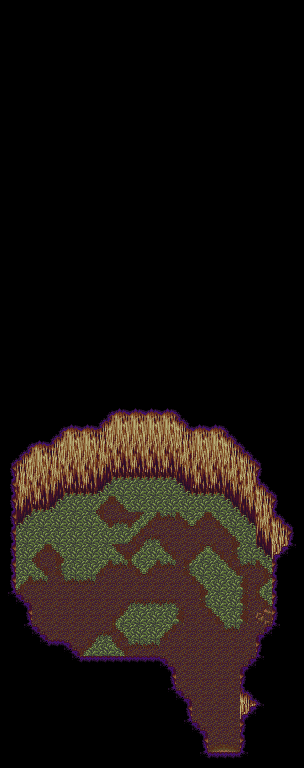

In [291]:
Image.open(s3)

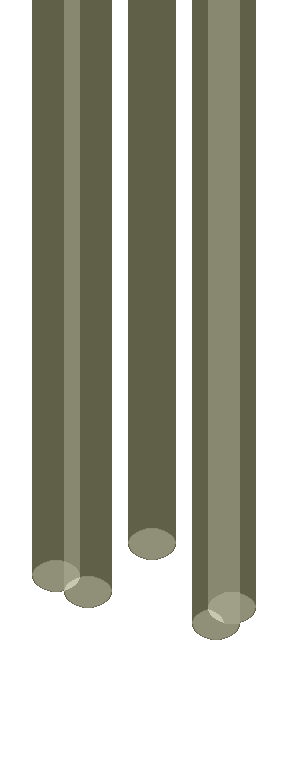

In [293]:
Image.open(s4)

In [295]:
arr_cave = np.asarray(Image.open(s3))
arr_lightmap = np.asarray(Image.open(s4))
arr_lightmap_2 = arr_lightmap.copy()  #we'll see why taking a copy is important soon
print(arr_lightmap_2)  #The mask color is [0,0,0]

[[[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 ...

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]

 [[0 0 0]
  [0 0 0]
  [0 0 0]
  ...
  [0 0 0]
  [0 0 0]
  [0 0 0]]]


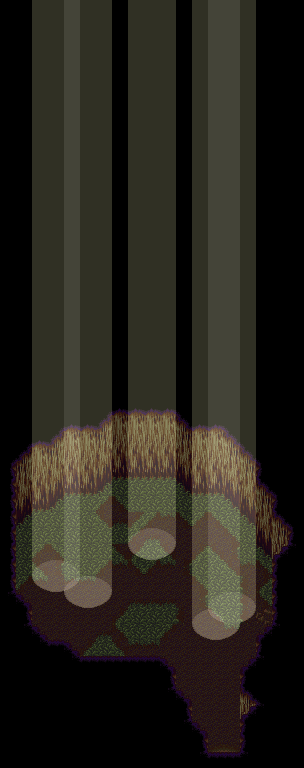

In [297]:
Image.fromarray(weighted_average(0.5, arr_cave, arr_lightmap))

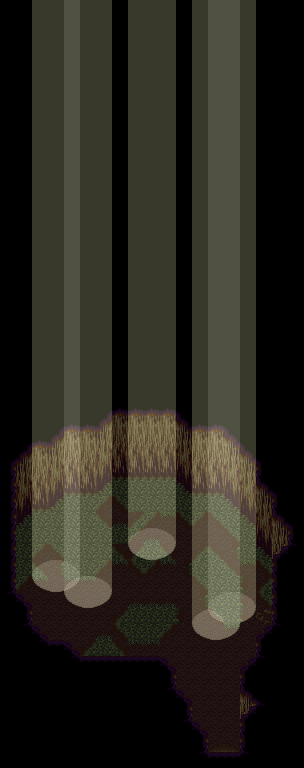

In [55]:
mask = [0, 0, 0]
transparent_layer(0.6, mask, arr_cave, arr_lightmap_2)

Conclusion: When you want to darken an image background, a regular weighted average also works well.

Recall: You can also save images that you generate as separate files. You just need to save the image as a variable first. See the code below

In [299]:
cave_img = Image.fromarray(weighted_average(0.5, arr_cave, arr_lightmap))
cave_img.save("cavelight.png")

drying_temple = transparent_layer(weights, mask, arr_temple, arr_watermap_2)
drying_temple.save("dryingtemple.png")

### Setting Colors 

__Goal:__ Change a horizontal band of the image to a single color.

In [301]:
import numpy as np
from PIL import Image
import os
import sys

In [303]:
img = Image.open("ash-lake.png")
arr = np.asarray(img)

Let's start by getting a horizontal band.

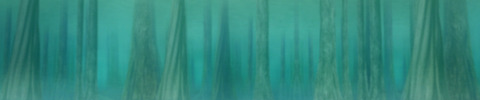

In [306]:
Image.fromarray(arr[200:300])

This is going to throw an error!

In [310]:
arr[200:300] = 0

ValueError: assignment destination is read-only

Main point: `img` and `arr` are _references_ to the image. What this means for us is that we can look, but we can't change anything. To get around this, we work on a copy!

In [312]:
B = arr.copy()

The size of `img` is SO small! This is because it's a reference.

In [315]:
sys.getsizeof(img)

48

The size of `arr` is still pretty small! 

In [317]:
sys.getsizeof(arr)

144

Now that `B` is not a reference to anything else, the values must be stored independently of `img`. This leads `B` to have a large size. 

In [321]:
sys.getsizeof(B)

691344

In [323]:
a = np.zeros((1000,1000))   #to compare how sizing works

In [325]:
b = a

In [327]:
sys.getsizeof(a)  #big array requires a larger size

8000128

In [329]:
sys.getsizeof(b) #b is a reference to a, but a is already large

8000128

In [331]:
B[200:300] = 0

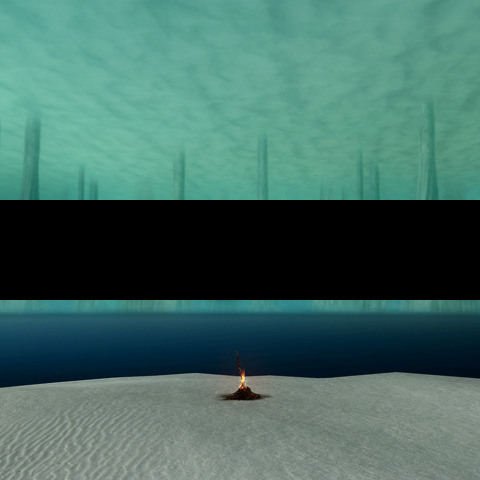

In [333]:
Image.fromarray(B)

In [335]:
B[200:300] = 255

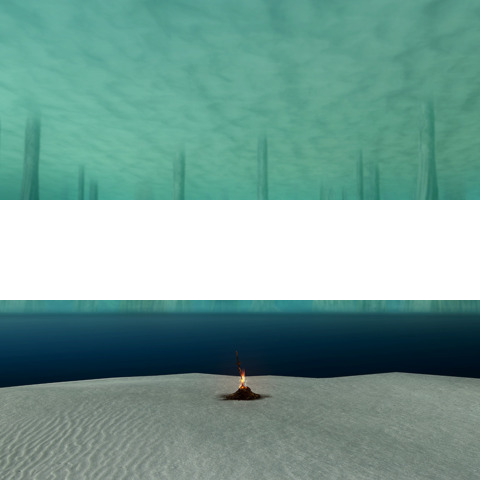

In [77]:
Image.fromarray(B)

Remember, `[83, 161, 148]` was the top-left-most color from earlier:

In [337]:
colors = np.array([83, 161, 148])

In [339]:
B[200:300].shape

(100, 480, 3)

In [341]:
colors.shape

(3,)

In [343]:
B[200:300] = colors

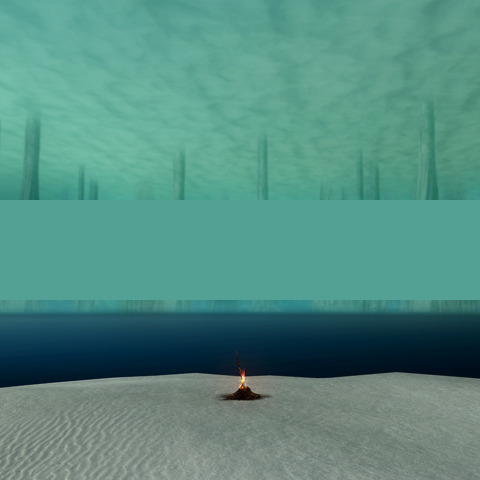

In [345]:
Image.fromarray(B)

Just for fun! From <a href="https://www.google.com/search?q=rgb+color+picker" target="_blank">Google's color picker</a>:

In [348]:
B[200:300] = np.array([234, 237, 197])

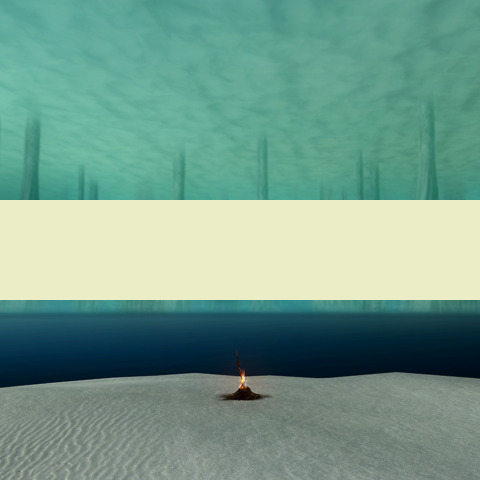

In [350]:
Image.fromarray(B)

### Making an image from scratch

In [111]:
from PIL import Image

In [113]:
arr = np.array([[[255,0,0],[0,255,0]],[[0,0,255],[255,255,0]]])
arr.shape

(2, 2, 3)

I'll start by making an error :)

In [116]:
Image.fromarray(arr)

TypeError: Cannot handle this data type: (1, 1, 3), <i4

The issue here is that I haven't specified a data type. What should it be?

In [121]:
arr = np.array([[[255,0,0],[0,255,0]],[[0,0,255],[255,255,0]]],dtype=np.uint8)

You might think there's another error when we run this...

In [124]:
img = Image.fromarray(arr)

In [126]:
img

No error, it's just 2 pixels by 2 pixels...super small and hard to see.

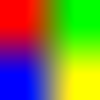

In [128]:
img.resize((100,100))

Maybe I don't like how it has extended the pixels (the blurring).

In [672]:
help(img.resize)

Help on method resize in module PIL.Image:

resize(size: 'tuple[int, int]', resample: 'int | None' = None, box: 'tuple[float, float, float, float] | None' = None, reducing_gap: 'float | None' = None) -> 'Image' method of PIL.Image.Image instance
    Returns a resized copy of this image.

    :param size: The requested size in pixels, as a 2-tuple:
       (width, height).
    :param resample: An optional resampling filter.  This can be
       one of :py:data:`Resampling.NEAREST`, :py:data:`Resampling.BOX`,
       :py:data:`Resampling.BILINEAR`, :py:data:`Resampling.HAMMING`,
       :py:data:`Resampling.BICUBIC` or :py:data:`Resampling.LANCZOS`.
       If the image has mode "1" or "P", it is always set to
       :py:data:`Resampling.NEAREST`. If the image mode specifies a number
       of bits, such as "I;16", then the default filter is
       :py:data:`Resampling.NEAREST`. Otherwise, the default filter is
       :py:data:`Resampling.BICUBIC`. See: :ref:`concept-filters`.
    :param box:

In [990]:
dir(Image.Resampling)

['BICUBIC',
 'BILINEAR',
 'BOX',
 'HAMMING',
 'LANCZOS',
 'NEAREST',
 '__abs__',
 '__add__',
 '__and__',
 '__bool__',
 '__ceil__',
 '__class__',
 '__contains__',
 '__delattr__',
 '__dir__',
 '__divmod__',
 '__doc__',
 '__eq__',
 '__float__',
 '__floor__',
 '__floordiv__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getnewargs__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__index__',
 '__init__',
 '__init_subclass__',
 '__int__',
 '__invert__',
 '__iter__',
 '__le__',
 '__len__',
 '__lshift__',
 '__lt__',
 '__members__',
 '__mod__',
 '__module__',
 '__mul__',
 '__name__',
 '__ne__',
 '__neg__',
 '__new__',
 '__or__',
 '__pos__',
 '__pow__',
 '__qualname__',
 '__radd__',
 '__rand__',
 '__rdivmod__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__rfloordiv__',
 '__rlshift__',
 '__rmod__',
 '__rmul__',
 '__ror__',
 '__round__',
 '__rpow__',
 '__rrshift__',
 '__rshift__',
 '__rsub__',
 '__rtruediv__',
 '__rxor__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__sub

In [311]:
for s in dir(Image.Resampling):
    if s[0] != '_' and s[0].isupper():
        print(s)

BICUBIC
BILINEAR
BOX
HAMMING
LANCZOS
NEAREST


There is an issue in how we join `s` to the end.

In [538]:
for s in dir(Image.Resampling):
    if s[0] != '_' and s[0].isupper():
        print(s)
        display(img.resize((100,100),resample=Image.Resampling.s))

BICUBIC


AttributeError: type object 'Resampling' has no attribute 's'

__Fix:__ Use `getattr` to call the variable `s`

BICUBIC


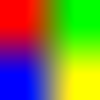

BILINEAR


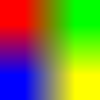

BOX


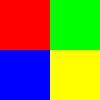

HAMMING


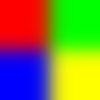

LANCZOS


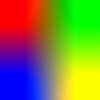

NEAREST


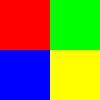

In [313]:
for s in dir(Image.Resampling):
    if s[0] != '_' and s[0].isupper():
        print(s)
        display(img.resize((100,100),resample=getattr(Image.Resampling,s)))

### Swapping color channels

__Goal:__ Want to swap the Red and Blue color channels.

In [354]:
import numpy as np
from PIL import Image
import os
import sys
img = Image.open("ash-lake.png")
arr = np.asarray(img)

In [356]:
arr

array([[[ 83, 161, 148],
        [ 83, 161, 148],
        [ 83, 161, 148],
        ...,
        [ 94, 157, 140],
        [ 94, 157, 140],
        [ 94, 157, 140]],

       [[ 83, 161, 148],
        [ 83, 161, 148],
        [ 83, 161, 148],
        ...,
        [ 93, 156, 139],
        [ 93, 156, 139],
        [ 93, 156, 139]],

       [[ 83, 161, 148],
        [ 83, 161, 148],
        [ 83, 161, 148],
        ...,
        [ 93, 156, 139],
        [ 92, 155, 138],
        [ 92, 155, 138]],

       ...,

       [[117, 128, 120],
        [140, 151, 143],
        [152, 163, 155],
        ...,
        [113, 126, 119],
        [117, 130, 123],
        [121, 134, 127]],

       [[128, 139, 131],
        [129, 140, 132],
        [124, 135, 127],
        ...,
        [112, 125, 118],
        [114, 127, 120],
        [116, 129, 122]],

       [[130, 141, 133],
        [118, 129, 121],
        [105, 117, 107],
        ...,
        [119, 132, 125],
        [120, 133, 126],
        [121, 134, 127]]

This might be trickier than you'd expect. I'll start by making a common mistake.

In [358]:
mylist = [ 83, 161, 148]
mylist[0] = mylist[2]  #mylist[0] original value is overwritten
mylist[2] = mylist[0]  #mylist[0] already equals mylist[2], so no change occurs.
mylist

[148, 161, 148]

Common way:

In [362]:
mylist = [ 83, 161, 148]
temp = mylist[0]
mylist[0] = mylist[2]
mylist[2] = temp
mylist

[148, 161, 83]

We want to use this idea and apply it to all of `arr`. Again, there will be mistakes here.

In [366]:
B = arr.copy()
temp = B[:,:,0] #Red values; pointing to B - if B changes, so does temp
B[:,:,0] = B[:,:,2]
B[:,:,2] = temp

In [368]:
B[0,0]

array([148, 161, 148], dtype=uint8)

In [370]:
temp2 = B[:,:,0].copy()

In [372]:
sys.getsizeof(temp)

128

In [374]:
sys.getsizeof(temp2)

230528

Here's how we can swap channels using the fact that `arr` is read-only

In [376]:
#Swaps the Red and Blue Channels
B_rb = arr.copy()
B_rb[:,:,0] = arr[:,:,2]  #You already made a copy, so take advantage of that. :)
B_rb[:,:,2] = arr[:,:,0]

In [378]:
B_rb[0,0]

array([148, 161,  83], dtype=uint8)

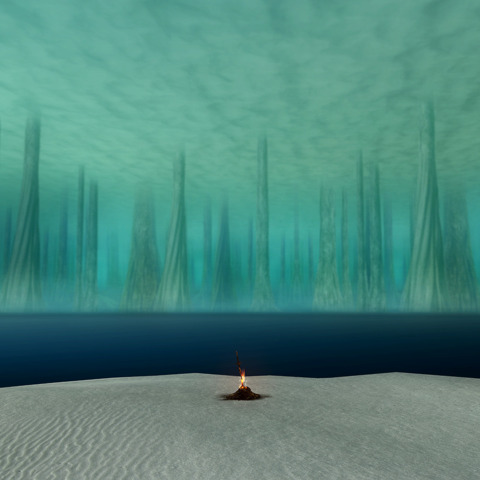

In [380]:
img

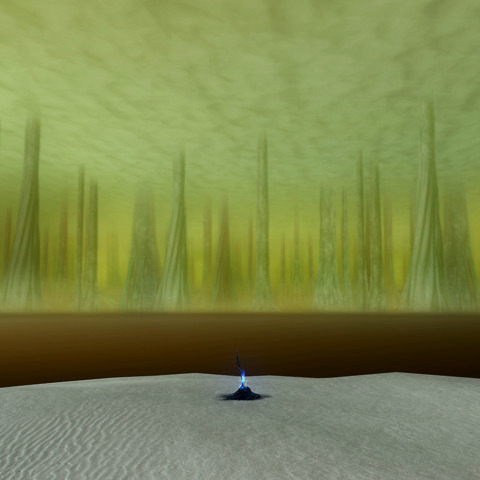

In [382]:
Image.fromarray(B_rb)

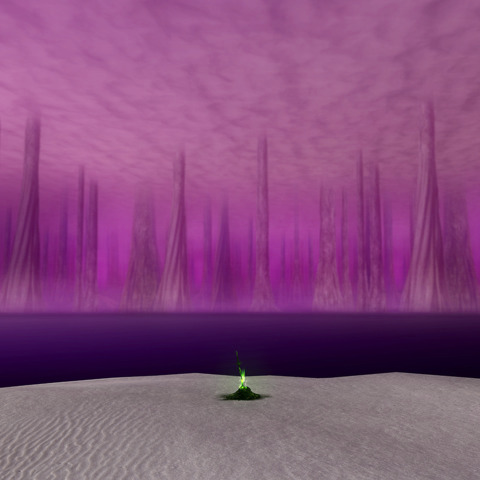

In [384]:
#Swaps the Red and Green Channels
B_rg = arr.copy()
B_rg[:,:,0] = arr[:,:,1]
B_rg[:,:,1] = arr[:,:,0]
Image.fromarray(B_rg)

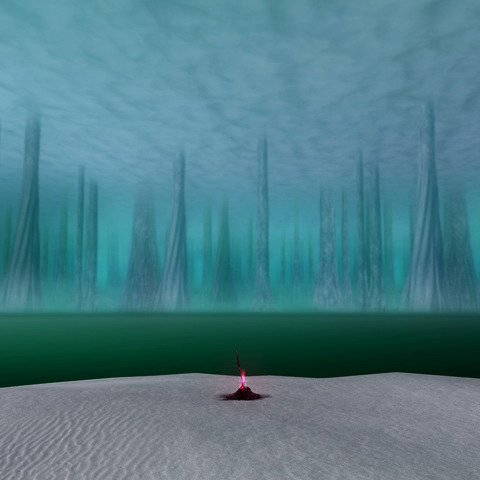

In [386]:
#Swaps the Green and Blue Channels
B_gb = arr.copy()
B_gb[:,:,1] = arr[:,:,2]
B_gb[:,:,2] = arr[:,:,1]
Image.fromarray(B_gb)

In practice, we can swap any two channels we want. We can even swap all 3 if we'd like. Let's make a function so it's easier to do.

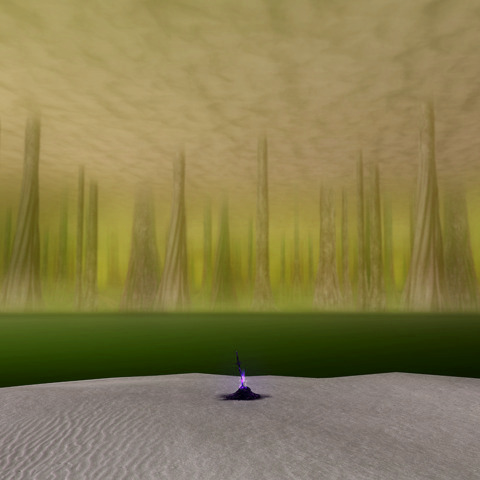

In [398]:
def channel_swap(arr, swap):
    B = arr.copy()
    B[:,:,0] = arr[:,:,swap[0]]
    B[:,:,1] = arr[:,:,swap[1]]
    B[:,:,2] = arr[:,:,swap[2]]
    return B

Z = channel_swap(arr, [1,2,0])
Image.fromarray(Z)

## Invert Colors

Each color channel is flipped from high to low and vice versa. If $C_{invert}$ is the new particular color, and $C_{old}$ is the original, we want

$C_{invert} = 255 - C_{old}$

This is very easy to broadcast across the entire array.

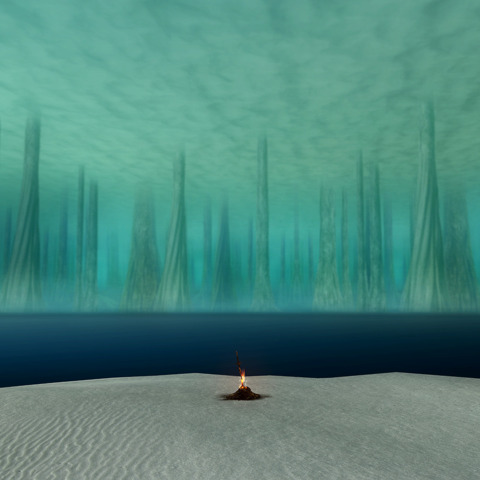

In [400]:
img

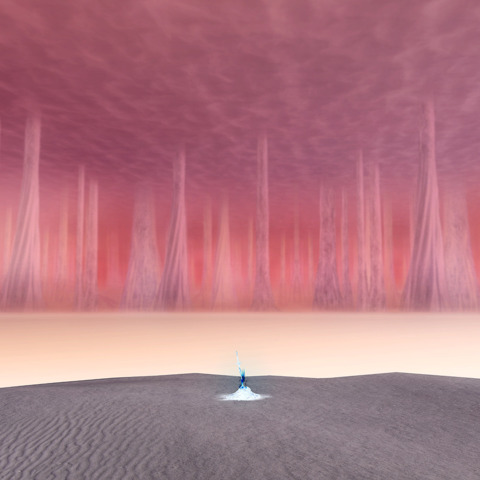

In [402]:
#invert colors, each RGB value is flipped opposite
B_inv = arr.copy()
B_inv = 255-B_inv  
Image.fromarray(B_inv)

We'll turn our code above into a function for future use.

In [404]:
def invert_colors(arr):
    B = arr.copy()
    B = 255 - B
    return B

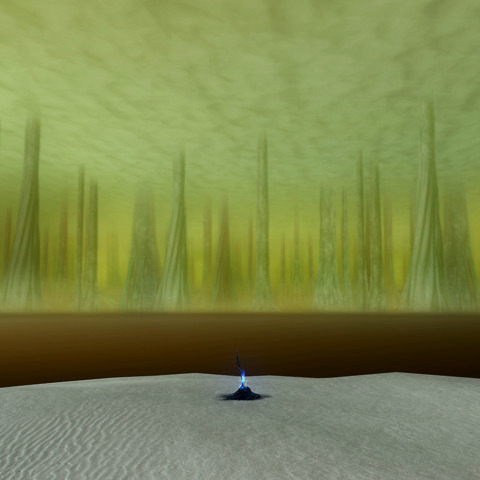

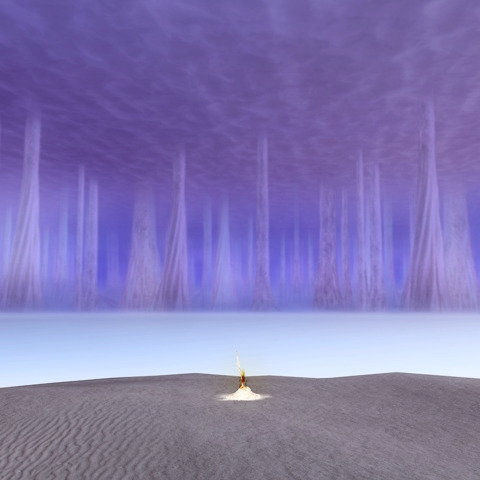

In [406]:
#invert colors on the Red-Blue swap
B_rb = channel_swap(arr, [2,1,0]) #we apply the functions one at a time in this cell. First channel swap
display(Image.fromarray(B_rb))
B_rb_inv = invert_colors(B_rb) #then invert colors. The order does not matter.
Image.fromarray(B_rb_inv)

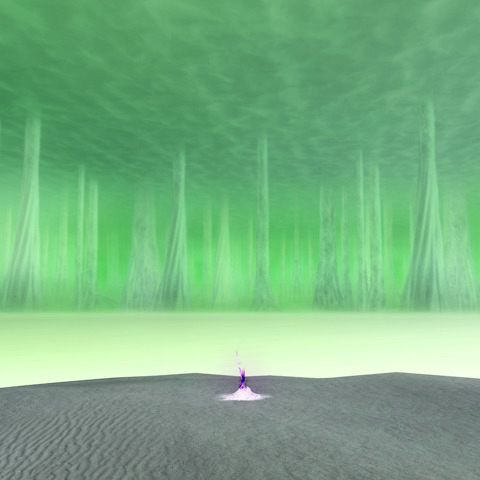

In [408]:
#invert colors on the Red-Green swap
B_rg_inv = invert_colors(channel_swap(arr, [1,0,2])) #both functions are nested in each other this time.
Image.fromarray(B_rg_inv)

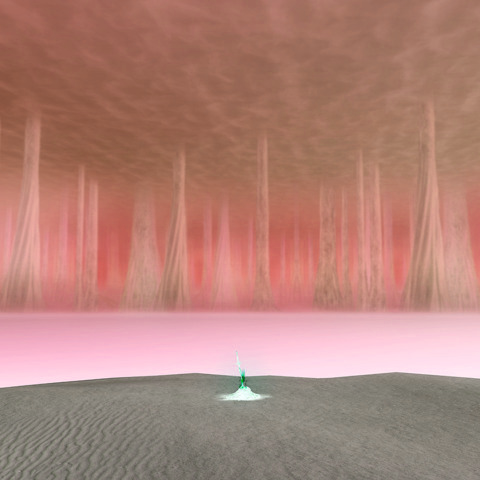

In [410]:
#invert colors on the Green-Blue swap
B_gb_inv = invert_colors(channel_swap(arr, [0,2,1])) #both functions are nested in each other this time.
Image.fromarray(B_gb_inv)

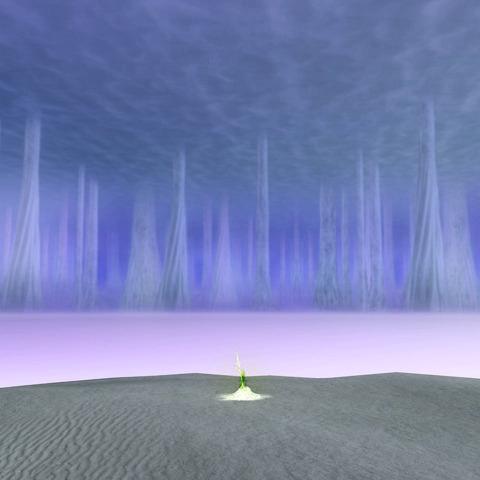

In [412]:
Z_inv = invert_colors(channel_swap(arr, [1,2,0]))
Image.fromarray(Z_inv)

In [420]:
def generalized_invert_colors(arr, C):  
    B = arr.copy()
    B = C - B #subtract C from B, instead of 255 from B
    return np.uint8(B)

arrshape = arr.shape
C = np.linspace(1,150,arrshape[1]).reshape(1,-1,1)

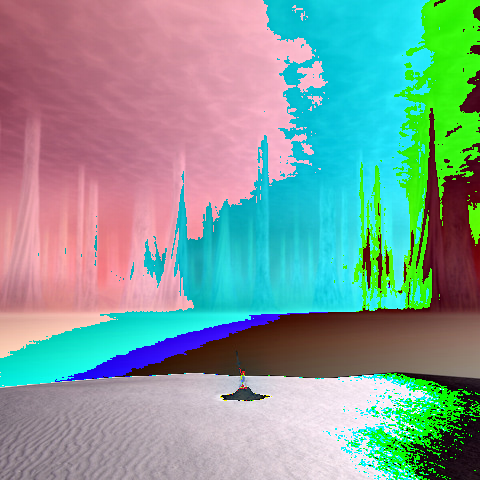

In [422]:
Image.fromarray(generalized_invert_colors(arr, C))

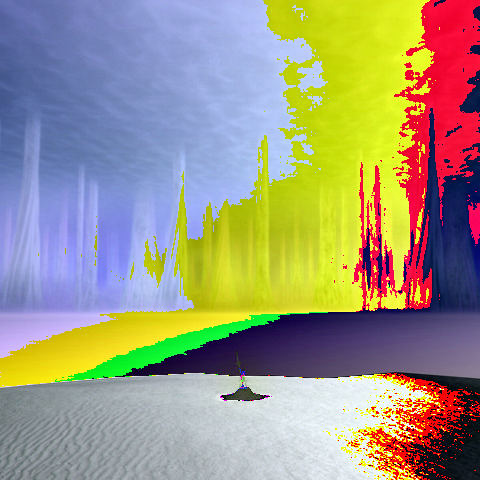

In [424]:
Image.fromarray(generalized_invert_colors(channel_swap(arr, [1,2,0]), C))

## Threshold filter

Across all 3 color channels, we set a Threshold value. Per pixel, any color channel with value above the threshold is set to a max of 255. Any color channel below this threshold is set to 0.

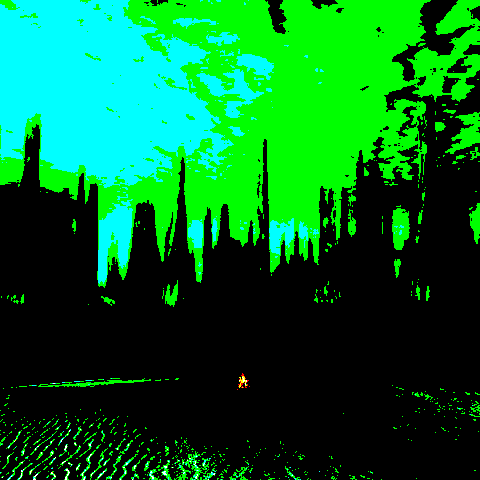

In [187]:
#Threshold filter
B = arr.copy()
B_th = np.empty_like(B)

thresh = 150  #color channels over this value will be increased to the max value, which is 255. Otherwise, they are 0.
#interesting values for this picture: thresh = 50, 70, 125, 150

B_th = np.uint8((B > thresh) * 255)

Image.fromarray(B_th)

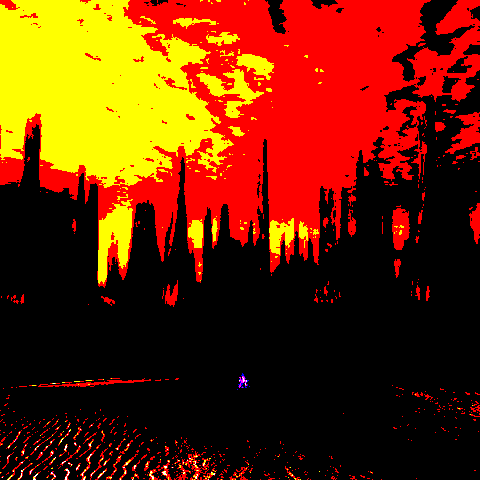

In [189]:
swap = [1,2,0]
B_th_channel = channel_swap(B_th, swap)
display(Image.fromarray(B_th_channel))

More animation here, at different threshold values.

In [192]:
l = np.array([0,1], dtype=np.uint8) 
thresholds = np.arange(20,201,2) 
anim_frames = []
for thresh in thresholds:
    B = arr.copy()
    B_th = np.empty_like(B)
    B_th = channel_swap(np.uint8((B > thresh) * 255), [1,2,0])
    img_frame = Image.fromarray(B_th)
    anim_frames.append(img_frame)

anim_frames = anim_frames + anim_frames[-1::-1]

In [207]:
save_anim(anim_frames, "ash_thresholds.gif")

## Brighten/Darken Image

In [426]:
import numpy as np
from PIL import Image
import os
img = Image.open("ash-lake.png")
arr = np.asarray(img)

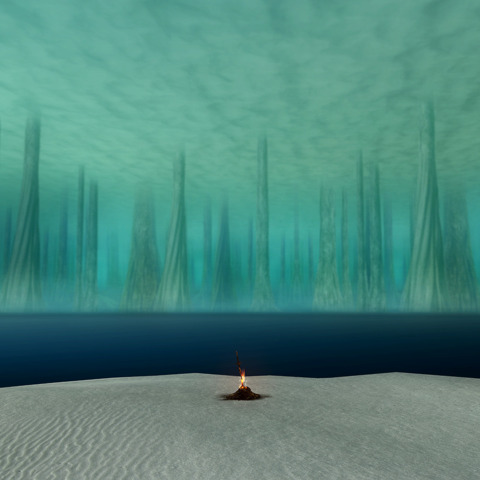

In [428]:
img

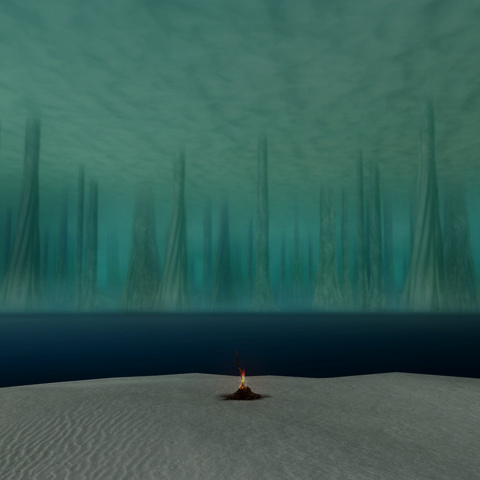

In [432]:
B_dark = arr.copy()

c = 0.7  #Darken, use constant between 0 and 1
B_dark = np.uint8(c*B_dark)  #pixels must be 8-bit integers.
Image.fromarray(B_dark)

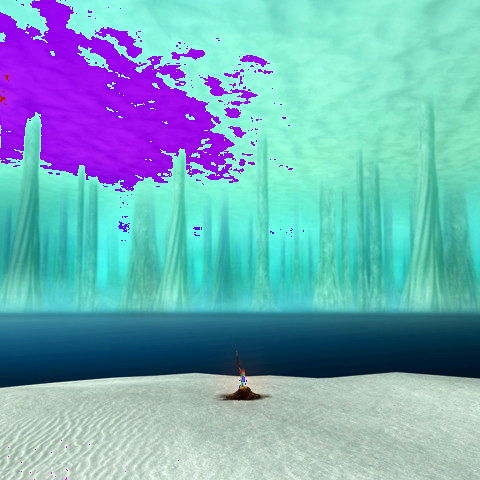

In [434]:
B = arr.copy()

c = 1.5 #Brighten, use constant greater than 1. 
#But too high constant causes some color channels to go above 255.
#c = 5 is gives weird and abstract rainbow colorings
#negative numbers also give weird colorings.
B = np.uint8(c*B)
Image.fromarray(B)

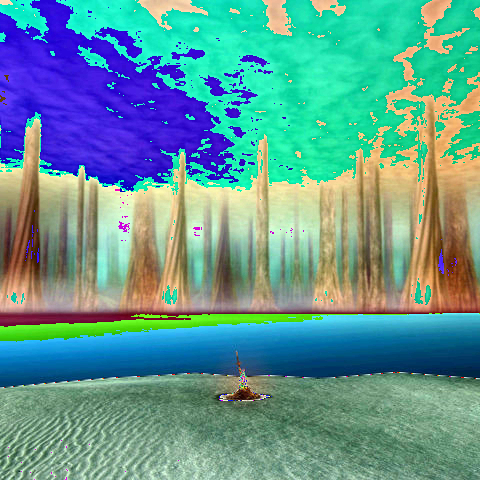

In [436]:
B = arr.copy()

c = 3 #Brighten gone wrong. The pixel values roll over.
B = np.uint8(c*B)
Image.fromarray(B)

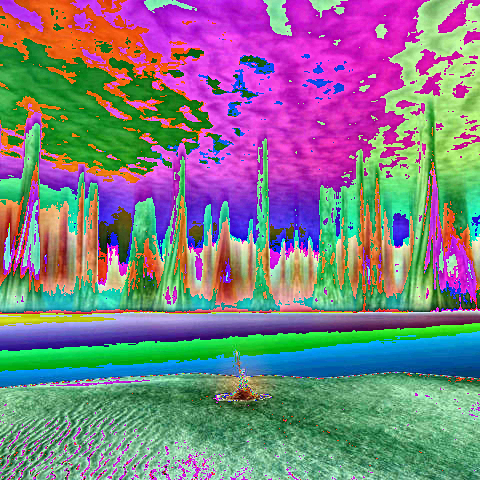

In [438]:
B = arr.copy()

c = 5 #More Brighten gone wrong. The pixel values roll over.
B = np.uint8(c*B)
Image.fromarray(B)

How weird can these colors get?

In [186]:
multipliers = np.linspace(1,10,200)
anim_frames = []
for c in multipliers:
    B = arr.copy()
    B = np.uint8(c*B)
    img_frame = Image.fromarray(B)
    anim_frames.append(img_frame)

anim_frames = anim_frames + anim_frames[-1::-1]

In [188]:
save_anim(anim_frames,"brightness_weird.gif")

An 8-bit integer has a maximum value of 255 (8 digits of binary). An overflow rolls over back to 0. You can think of this as doing operations mod 256. High multiples magnify the difference between colors, which is why the colors start to scatter.

To fix these issues, we have to replace any color channel above 255 with exactly 255, before we convert to `np.uint8` type. Boolean indexing comes in handy here.

In [440]:
B = np.float64(arr.copy())

c = 3

B = c*B
B  #now we can see what the values are before they roll over.

array([[[249., 483., 444.],
        [249., 483., 444.],
        [249., 483., 444.],
        ...,
        [282., 471., 420.],
        [282., 471., 420.],
        [282., 471., 420.]],

       [[249., 483., 444.],
        [249., 483., 444.],
        [249., 483., 444.],
        ...,
        [279., 468., 417.],
        [279., 468., 417.],
        [279., 468., 417.]],

       [[249., 483., 444.],
        [249., 483., 444.],
        [249., 483., 444.],
        ...,
        [279., 468., 417.],
        [276., 465., 414.],
        [276., 465., 414.]],

       ...,

       [[351., 384., 360.],
        [420., 453., 429.],
        [456., 489., 465.],
        ...,
        [339., 378., 357.],
        [351., 390., 369.],
        [363., 402., 381.]],

       [[384., 417., 393.],
        [387., 420., 396.],
        [372., 405., 381.],
        ...,
        [336., 375., 354.],
        [342., 381., 360.],
        [348., 387., 366.]],

       [[390., 423., 399.],
        [354., 387., 363.],
        [315., 3

In [442]:
B > 255 #find the values that overflow

array([[[False,  True,  True],
        [False,  True,  True],
        [False,  True,  True],
        ...,
        [ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True]],

       [[False,  True,  True],
        [False,  True,  True],
        [False,  True,  True],
        ...,
        [ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True]],

       [[False,  True,  True],
        [False,  True,  True],
        [False,  True,  True],
        ...,
        [ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True]],

       ...,

       [[ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True],
        ...,
        [ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True]],

       [[ True,  True,  True],
        [ True,  True,  True],
        [ True,  True,  True],
        ...,
        [ True,  True,  True],
        [ True,  True,  True],
        [ True,

In [212]:
255*(B>255) #True counts as 1, False counts as 0, so we multiply by 255

array([[[  0, 255, 255],
        [  0, 255, 255],
        [  0, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[  0, 255, 255],
        [  0, 255, 255],
        [  0, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[  0, 255, 255],
        [  0, 255, 255],
        [  0, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]

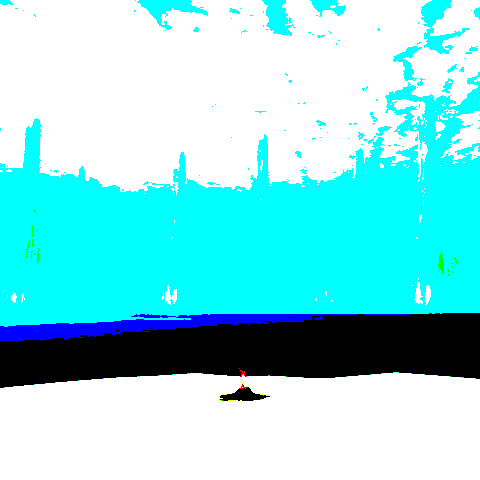

In [444]:
Image.fromarray(np.uint8(255*(B > 255)))   #visualize all of the color channels that overflow, for fun. 

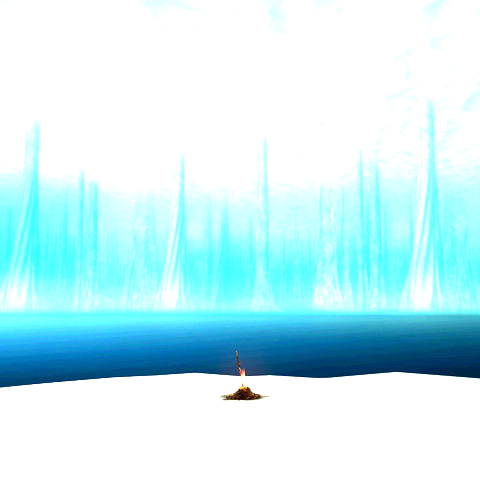

In [446]:
B[B > 255] = 255
Image.fromarray(np.uint8(B)) #The final result

We combine our work into one function, all in one cell. _Note: There are smarter brightness algorithms than this._

In [448]:
def adjust_lighting(arr, c):
    L = np.float64(arr.copy())
    L = c*L
    L[L > 255] = 255
    return np.uint8(L)

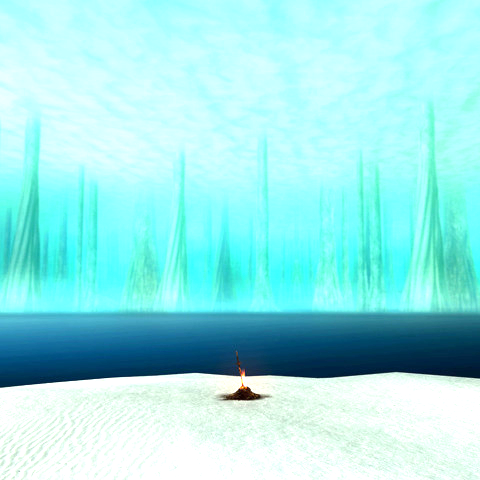

In [450]:
c = 2
bright_ash = adjust_lighting(arr,c)
Image.fromarray(bright_ash)

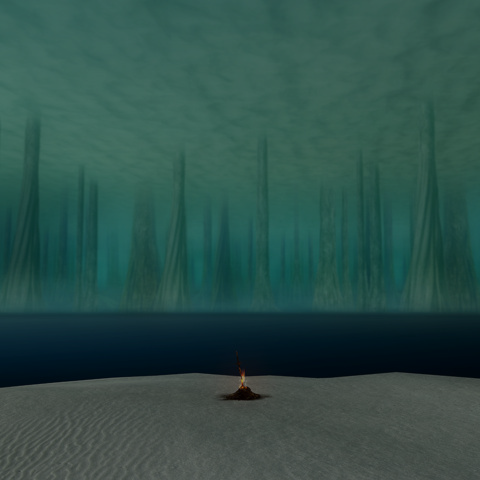

In [452]:
dark_ash = adjust_lighting(arr,0.6)
Image.fromarray(dark_ash)

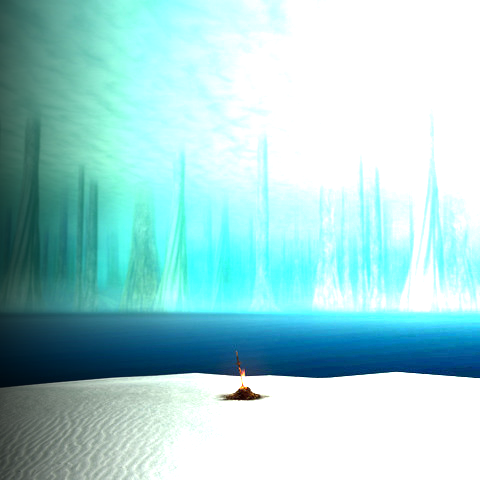

In [205]:
arrshape = arr.shape
C = np.linspace(0.5,4.5,arrshape[1]).reshape(1,-1,1)  #Broadcast this row across the entire tensor array
shine_ash = adjust_lighting(arr,C)
Image.fromarray(shine_ash)

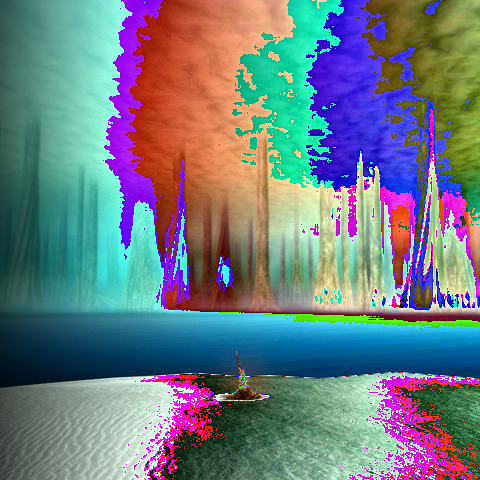

In [207]:
Image.fromarray(np.uint8(C*arr)) #Compare the result above to what happens when we don't limit the maximum value to 255.

In [237]:
arrshape = arr.shape
C = np.linspace(0.7,3,arrshape[1]//2).reshape(1,-1,1)
C = np.concatenate([C, C[:,::-1,:]], axis=1)
anim_frames = []
for _ in np.arange(0,arrshape[1],arrshape[1]//20):
    #B = arr.copy()
    shine_ash = adjust_lighting(arr,C)
    img_frame = Image.fromarray(shine_ash)
    anim_frames.append(img_frame)
    C = np.concatenate([C[:,-24::,:], C[:,:-24:,:]], axis=1)

In [660]:
save_anim(anim_frames,"ash_shine_flow.gif")

## Grayscale Filter

Gray colors occur when Red = Green = Blue for a particular pixel. But there are easier ways to generate grayscale pictures.

Tensors of shape $(r, c, 3)$ give color pictures. Matrices of shape $(r,c)$ give grayscale images.

In [456]:
gray_range = np.arange(0,256).reshape(16,16)

In [458]:
img_gr = Image.fromarray(np.uint8(gray_range))
img_gr

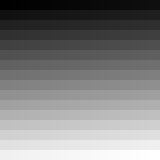

In [215]:
n = 10
Expander = np.ones((n,n))
big_gr = np.kron(gray_range, Expander)  #each single number in gray_range is expanded to an nxn block of all the same value
Image.fromarray(np.uint8(big_gr))

Let's make a grayscale image of Ash lake, just from its red channel. Compare this to the green and blue channels, too.

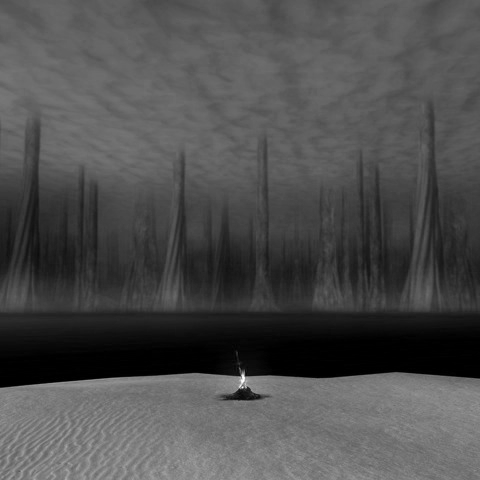

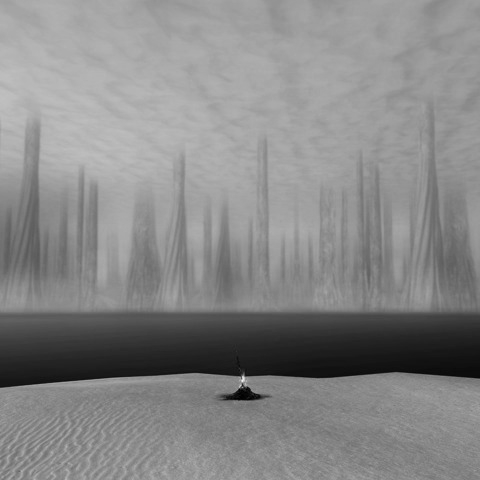

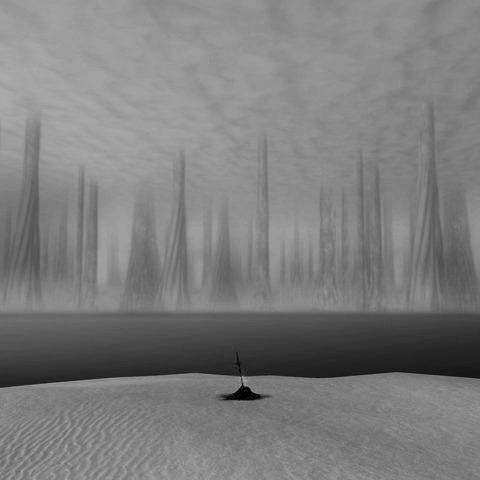

In [217]:
display(Image.fromarray(np.uint8(arr[:,:,0])))   #red channel
display(Image.fromarray(np.uint8(arr[:,:,1])))     #green channel
display(Image.fromarray(np.uint8(arr[:,:,2])))    #blue channel

### A better algorithm for grayscale
For each pixel $(i,j)$ of color image $Y$, you can use the formula $Y_{ij} = 0.2125\times Red_{ij} + 0.7154\times Green_{ij} + 0.0721\times Blue_{ij}$ This specific combination of colors is used often in image processing, and can be found on the <a href="https://en.wikipedia.org/wiki/Grayscale"> Wikipedia page for Grayscale</a>

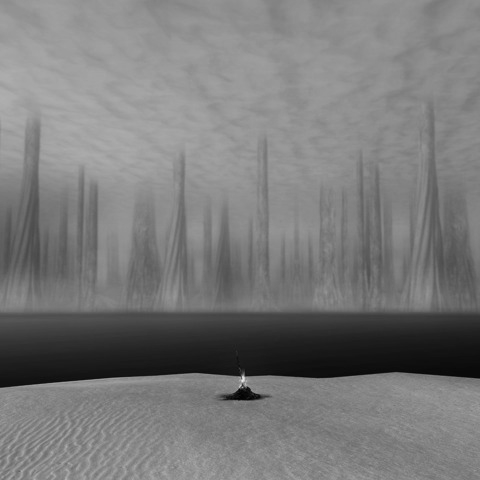

In [460]:
Y = arr
Y_bettergray = np.uint8(0.2125*Y[:,:,0] + 0.7154*Y[:,:,1] + 0.0721*Y[:,:,2])
Image.fromarray(Y_bettergray)

In [251]:
Y_bettergray.shape

(480, 480)

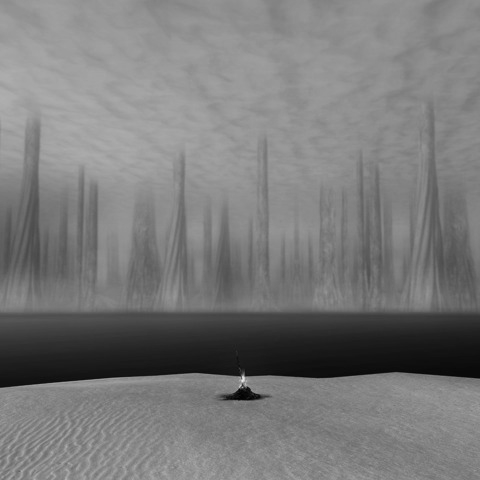

In [462]:
grayscale = lambda arr: np.uint8(0.2125*Y[:,:,0] + 0.7154*Y[:,:,1] + 0.0721*Y[:,:,2])  #function version
Image.fromarray(grayscale(Y))

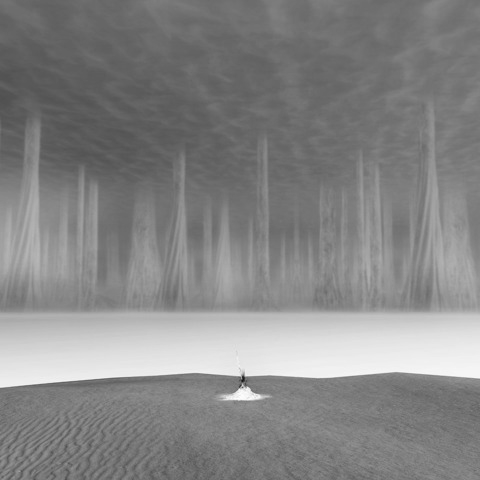

In [464]:
Image.fromarray(invert_colors(grayscale(Y)))

## Sepia Filter

This is similar to the Grayscale filter, but each new color channel gets a different combination of the original color channels. The constants used here are apparently recommended by Microsoft (though I can no longer find the source for this attribution).

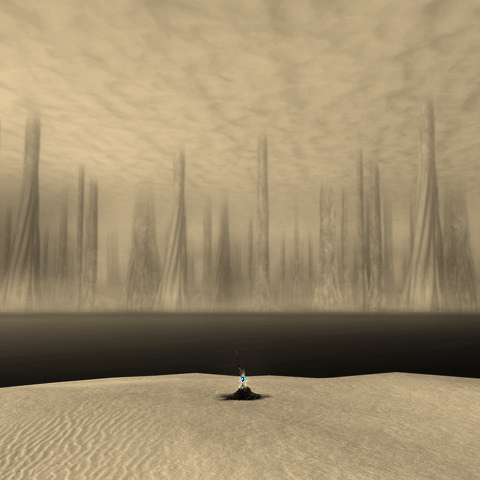

In [466]:
S = arr
S_sepia = np.zeros_like(S)
S_sepia[:,:,0] = 0.393*S[:,:,0] + 0.769*S[:,:,1] + 0.189*S[:,:,2]
S_sepia[:,:,1] = 0.349*S[:,:,0] + 0.686*S[:,:,1] + 0.168*S[:,:,2]
S_sepia[:,:,2] = 0.272*S[:,:,0] + 0.534*S[:,:,1] + 0.131*S[:,:,2]

Image.fromarray(np.uint8(S_sepia))

In [261]:
S_sepia.shape

(480, 480, 3)

We still need to stop any color channels from overflowing beyond 255

In [468]:
def sepia_filter(S):
    S_sepia = np.float64(np.zeros_like(S))
    S_sepia[:,:,0] = 0.393*S[:,:,0] + 0.769*S[:,:,1] + 0.189*S[:,:,2]
    S_sepia[:,:,1] = 0.349*S[:,:,0] + 0.686*S[:,:,1] + 0.168*S[:,:,2]
    S_sepia[:,:,2] = 0.272*S[:,:,0] + 0.534*S[:,:,1] + 0.131*S[:,:,2]
    
    S_sepia[S_sepia > 255] = 255
    return np.uint8(S_sepia)

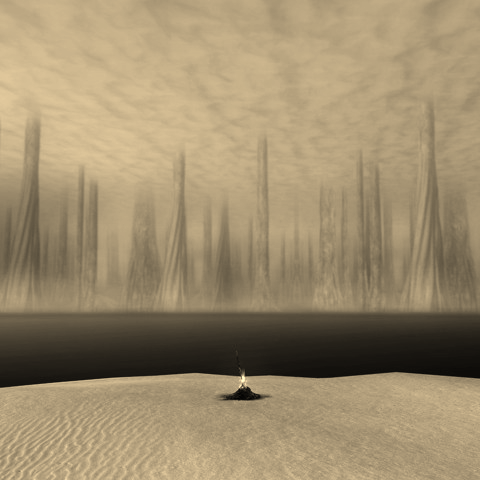

In [470]:
Image.fromarray(sepia_filter(S))

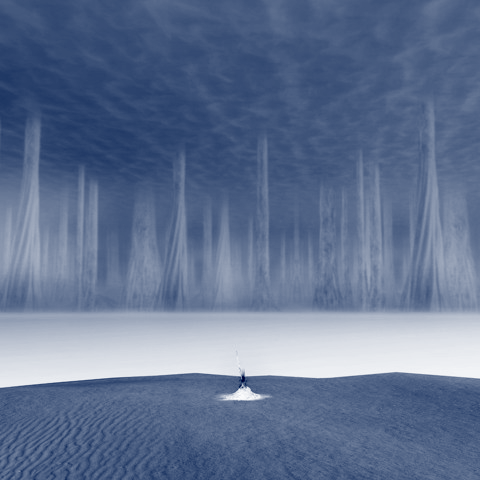

In [472]:
W = invert_colors(sepia_filter(S))
Image.fromarray(W)

## Gradient filter

You can generalize the sepia filter by replacing the colors in your image with any other gradient or color map.

The code we'll follow bellow will be broken down into 3 big steps:
- Generate a gradient
- Convert your image to grayscale
- Replace the gray colors with your gradient color.

### Duotone filter - Generate a two-color gradient and use it to recolor your image

In [476]:
def duotone_gradient(color1, color2):
    Duo_gradient = np.zeros((256, 3))
    
    for i in range(3):
        Duo_gradient[:, i] = np.linspace(color1[i], color2[i], 256)
    return np.uint8(Duo_gradient)

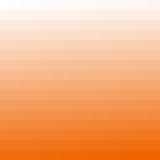

In [478]:
#Theme: Creamsicle
color1 = [255,255,255]  #white 
color2 = [240,100,0]   #orange

Creamsicle_gradient = duotone_gradient(color1, color2)

display(Image.fromarray(Creamsicle_gradient.reshape(1,256,3)))

Grad_view = Creamsicle_gradient.reshape(16,16,3)
display(Image.fromarray(Grad_view))

n = 10
Expander = np.ones((n,n))
big_grad = np.zeros((n*16, n*16, 3))
for i in range(3):
    big_grad[:,:,i] = np.kron(Grad_view[:,:,i], Expander)
Image.fromarray(np.uint8(big_grad))

(480, 480, 3)


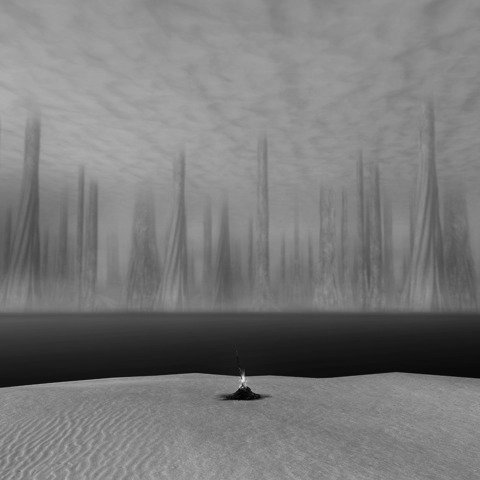

In [480]:
D = arr.copy()
D_gray = grayscale(D)
D_gray = D_gray.reshape(D.shape[0],D.shape[1],1)
D[:,:,:] = D_gray
print(D.shape)
Image.fromarray(np.uint8(D))

In [482]:
def gradient_filter(D, gradient):
    Du = D.copy()
    D_gray = grayscale(Du)
    for channel in range(3):
        Mask = np.ones_like(D_gray).reshape(D.shape[0],D.shape[1])
        for color in range(Du.min(), Du.max()+1):
            Mask[(Mask == 1) & (Du[:,:,channel] == color)] = 2  #flags any channel that matches the color in that channel
            Du[:,:,channel][(Du[:,:,channel] == color) & (Mask == 2)] = gradient[color,channel]  #changes the colors according to which channels are flagged.
            Mask[Mask == 2] = 0 #Mark these channels as no longer needing to be changed.
    return np.uint8(Du)

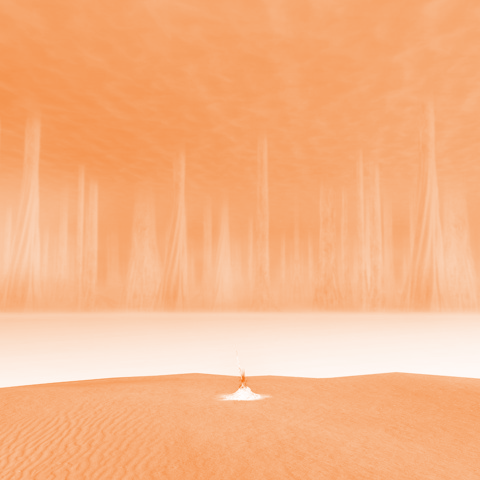

In [484]:
Creamsicle_filter = gradient_filter(D, Creamsicle_gradient)

Image.fromarray(Creamsicle_filter)

Try some of the other color choices below, or pick any two colors you want with the help of <a href="https://www.google.com/search?q=rgb+color+picker"> rgb color picker </a>

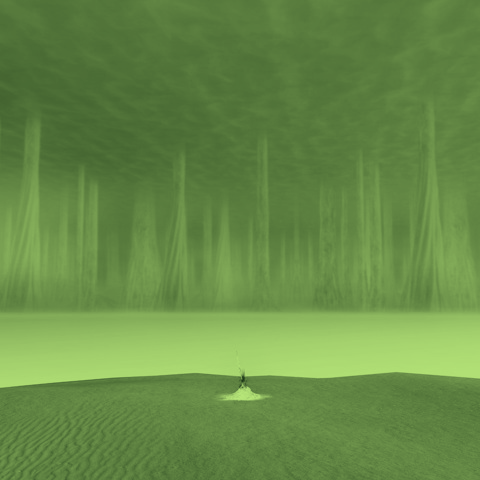

In [486]:
#Theme: Retro Nightvision
color1 =  [184,232,122]  #bright green 
color2 = [15, 40, 15]  #dark green

your_gradient = duotone_gradient(color1, color2)

display(Image.fromarray(your_gradient.reshape(16,16,3)))

your_filter = gradient_filter(D, your_gradient)

Image.fromarray(your_filter)

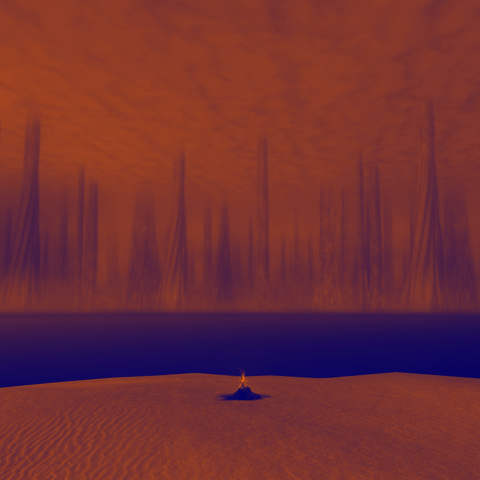

In [500]:
#Theme: Pumpkin Hill
color1 = [0,0,100]  #dark blue      
color2 = [240,100,0]  #orange

Pumpkin_gradient = duotone_gradient(color1, color2)

display(Image.fromarray(Pumpkin_gradient.reshape(16,16,3)))

Pumpkin_filter = gradient_filter(D, Pumpkin_gradient)

Image.fromarray(Pumpkin_filter)

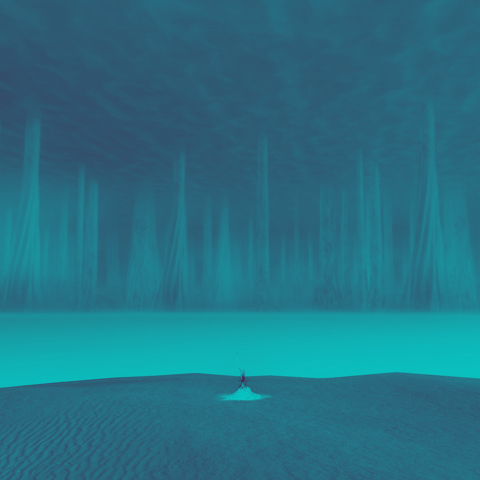

In [498]:
#Theme: Winter 2026 9am
color1 = [8, 199, 196]     
color2 = [71, 21, 65]

Your_gradient = duotone_gradient(color1, color2)

display(Image.fromarray(Your_gradient.reshape(16,16,3)))

Your_filter = gradient_filter(D, Your_gradient)

Image.fromarray(Your_filter)

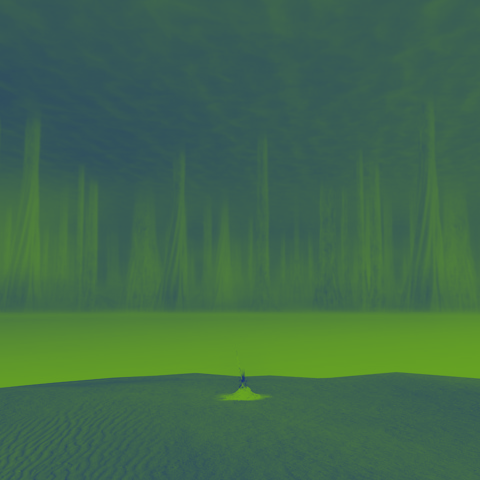

In [502]:
#Theme: Winter 2026 10am
color1 = [105, 168, 32]     
color2 = [21, 39, 125]

Your_gradient = duotone_gradient(color1, color2)

display(Image.fromarray(Your_gradient.reshape(16,16,3)))

Your_filter = gradient_filter(D, Your_gradient)

Image.fromarray(Your_filter)

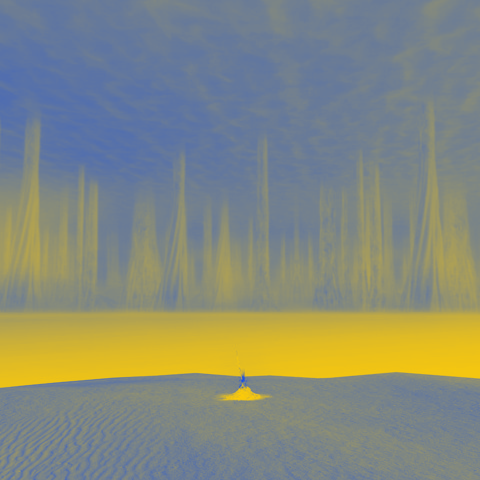

In [251]:
#Theme: UCI
color1 = [254, 204, 7] #gold, from https://brand.uci.edu/identity/colors.php
color2 = [0, 66, 255] #blue, used above link as a reference, then went brighter, more saturated

UCI_gradient = duotone_gradient(color1, color2)

display(Image.fromarray(UCI_gradient.reshape(16,16,3)))

UCI_filter = gradient_filter(D, UCI_gradient)

Image.fromarray(UCI_filter)

### Other gradients, and other color replacement

There's nothing special about using duotone gradients in the filter above. You can use any other gradient, or any other array of 256 values to determine your image colors.

In [339]:
gray_gradient = duotone_gradient([0,0,0], [255,255,255])
print(gray_gradient.shape)
sep_gradient = sepia_filter(gray_gradient.reshape(16,16,3))
Image.fromarray(sep_gradient)

(256, 3)


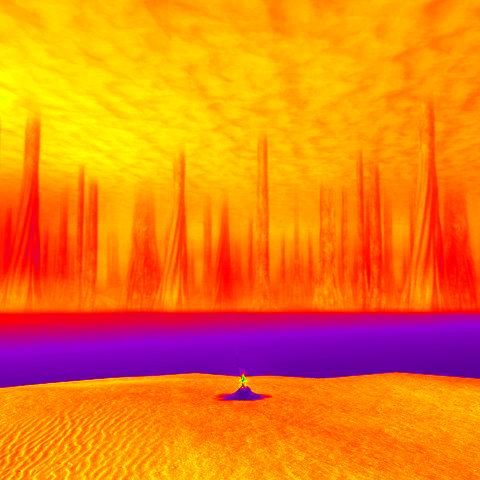

In [718]:
rainbow_colors = [
        [75, 0, 130],   # Indigo        
        [148, 0, 211],   # Violet
        [255, 0, 0],    # Red
        [255, 127, 0],  # Orange
        [255, 255, 0],  # Yellow
        [0, 255, 0],    # Green
        [0, 0, 255]    # Blue
    ]

rainbow_gradient = np.zeros((258, 3)) #43*6 = 258. Needed because 43 does not divide evenly into 256, but it divides evenly into 258
for h in range(6):
    for i in range(3):
        rainbow_gradient[43*h:43*(h+1), i] = np.linspace(rainbow_colors[h][i], rainbow_colors[h+1][i], 43)  #43*6 = 258

rainbow_gradient = np.uint8(rainbow_gradient[:256]) #clip the extra two colors from the end of this image, to get 256 colors and not 258.
display(Image.fromarray(rainbow_gradient.reshape(16,16,3)))

rainbow_filter = gradient_filter(D, rainbow_gradient)

Image.fromarray(rainbow_filter)

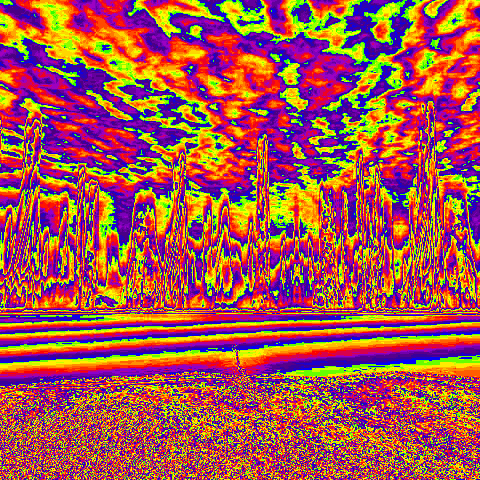

In [722]:
rainbow_transpose_gradient = rainbow_gradient.copy().reshape(16,16,3).transpose((1,0,2))

display(Image.fromarray(rainbow_transpose_gradient))

rainbow_transpose_gradient = rainbow_transpose_gradient.reshape(256,3)

rainbow_transpose_filter = gradient_filter(D, rainbow_transpose_gradient)

Image.fromarray(rainbow_transpose_filter)

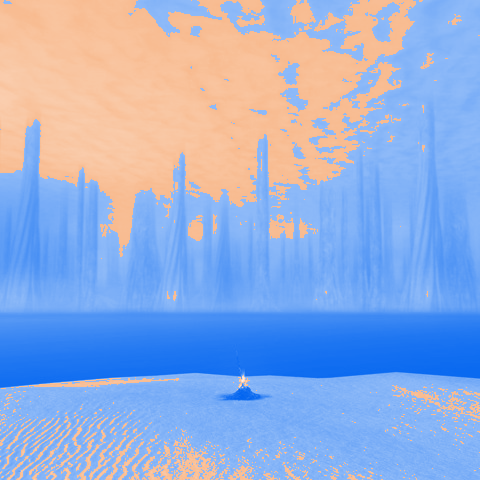

In [329]:
display(Image.fromarray(channel_swap(Creamsicle_gradient[:144:-1,::].reshape(1,-1,3),[2,1,0])))
display(Image.fromarray(Creamsicle_gradient[144::-1,::].reshape(1,-1,3)))
split = 112
Combo_gradient = np.concatenate((Creamsicle_gradient[:split:-1,::-1], Creamsicle_gradient[split::-1,::]))
Combo_filter = gradient_filter(D, Combo_gradient)
display(Image.fromarray(Combo_gradient.reshape(16,16,3)))
display(Image.fromarray(Combo_filter))

In [331]:
color1 = [255,255,255]  #white 
color2 = [240,100,0]   #orange

Creamsicle_gradient = duotone_gradient(color1, color2)

anim_frames = []

for split in np.arange(0,256,4):
    Combo_gradient = np.concatenate((Creamsicle_gradient[:split:-1,::-1], Creamsicle_gradient[split::-1,::]))
    Combo_filter = gradient_filter(D, Combo_gradient)
    Combo_filter[:16:,:16:,::] = Combo_gradient.reshape(16,16,3) #pastes the gradient into the frames of the image
    img_frame = Image.fromarray(Combo_filter)
    anim_frames.append(img_frame)

for split in np.arange(0,256,4):
    Combo_gradient = np.concatenate((Creamsicle_gradient[:split:-1,::], Creamsicle_gradient[split::-1,::-1]))
    Combo_filter = gradient_filter(D, Combo_gradient)
    Combo_filter[:16:,:16:,::] = Combo_gradient.reshape(16,16,3) #pastes the gradient into the frames of the image
    img_frame = Image.fromarray(Combo_filter)
    anim_frames.append(img_frame)
    #if split%3 == 0:
    #    display(img_frame)

In [762]:
save_anim(anim_frames, "Ash_orange_blue.gif", 100)

## White Noise, Colorful Noise

In [335]:
import numpy as np
from PIL import Image
import os

In [337]:
rng = np.random.default_rng()
R = rng.integers(0,255,[100,700])

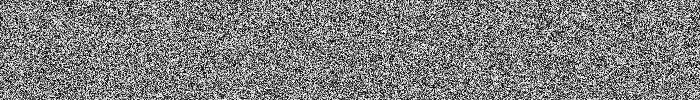

In [339]:
Image.fromarray(np.uint8(R))

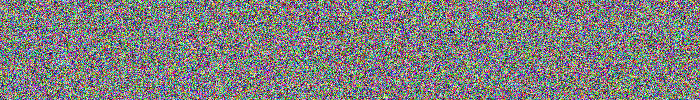

In [341]:
R_color = rng.integers(0,255,[100,700,3])
Image.fromarray(np.uint8(R_color))

We can blend noise into our images by taking a weighted average our image and a noise image.

In [344]:
img = Image.open("ash-lake.png")
arr = np.asarray(img)

weighted_average = lambda weight, arr1, arr2: np.uint8((1-weight)*arr1 + weight*arr2)

def invert_colors(arr):
    B = arr.copy()
    B = 255 - B
    return B

def channel_swap(arr, swap):
    B = arr.copy()
    B[:,:,0] = arr[:,:,swap[0]]
    B[:,:,1] = arr[:,:,swap[1]]
    B[:,:,2] = arr[:,:,swap[2]]
    return B

def adjust_lighting(arr, c):
    L = np.float64(arr.copy())
    L = c*L
    L[L > 255] = 255
    return np.uint8(L)

B_rb_inv = invert_colors(channel_swap(arr, [2,1,0]))


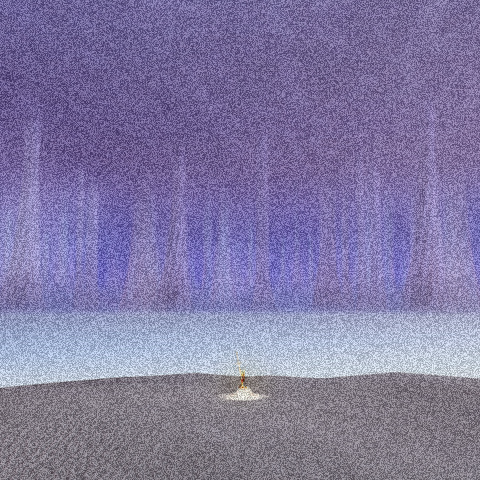

In [346]:
R2 = rng.integers(0,255,(480,480,1))
Image.fromarray(weighted_average(0.3, B_rb_inv, R2))  #Weight the two images together, like in the example earlier in this notebook.

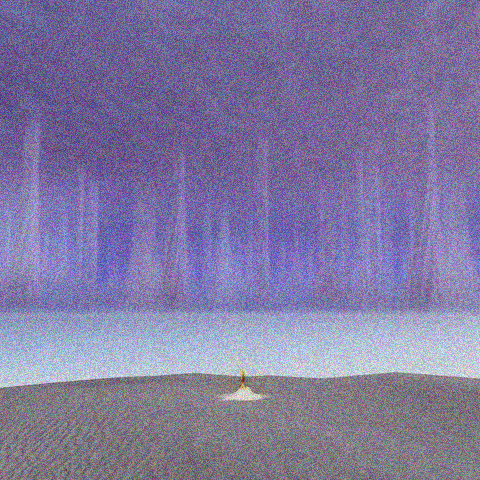

In [348]:
R_color2 = rng.integers(0,255,arr.shape)  #get the size of the random array from the image array
Image.fromarray(weighted_average(0.3, B_rb_inv, R_color2)) #Weight the two images together, like in the example earlier in this notebook.

### More blending modes

These blend modes are found in common photo editing software. Reference: <a href= "https://en.wikipedia.org/wiki/Blend_modes"> Blend modes - Wikipedia </a>

#### Lighten Only:
Across each individual pixel and color channel, take the maximum. Brighter colors have higher numbers

In [352]:
lighten_only = lambda arr1, arr2: np.uint8(np.maximum(arr1, arr2))
#Note: np.maximum is different from np.max!
#np.maximum compares 2 arrays component-wise and returns the largest values
#np.max finds the single largest element in one array (or along an axis, depending on your inputs)

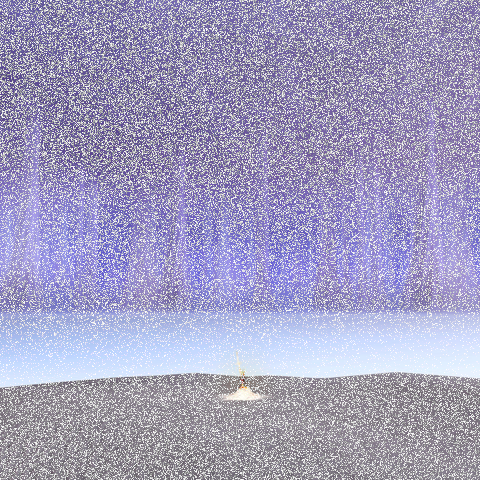

In [354]:
display(Image.fromarray(lighten_only(R2, B_rb_inv)))

#### Darken Only:
Across each individual pixel and color channel, take the minimum. Darker colors have smaller numbers

In [357]:
darken_only = lambda arr1, arr2: np.uint8(np.minimum(arr1, arr2))
#Similarly, np.minimum is different from np.min!
#np.minimum compares 2 arrays component-wise and returns the smallest values
#np.min finds the single smallest element in one array (or along an axis, depending on your inputs)

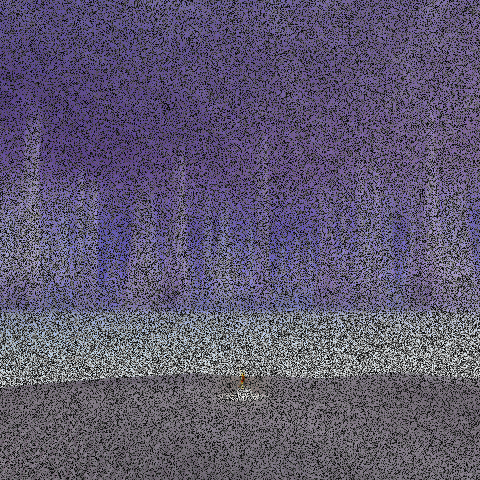

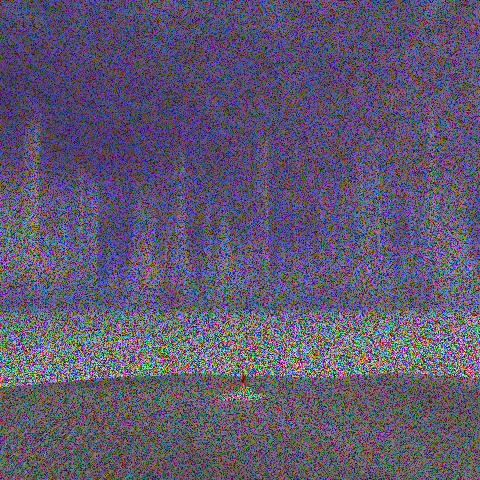

In [359]:
display(Image.fromarray(darken_only(R2, B_rb_inv)))
display(Image.fromarray(darken_only(R_color2, B_rb_inv)))

images\Cloud.png


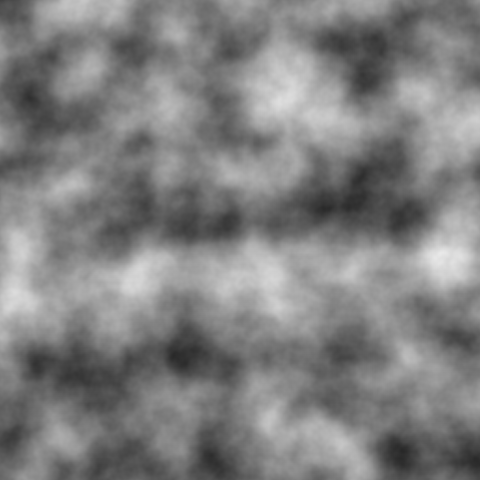

In [361]:
s = os.path.join("images",'Cloud.png')
print(s)
img = Image.open(s)
arr_c = np.zeros((480,480,3))
arr_c[:,:,:] = np.asarray(img).reshape(480,480,1)
display(img)

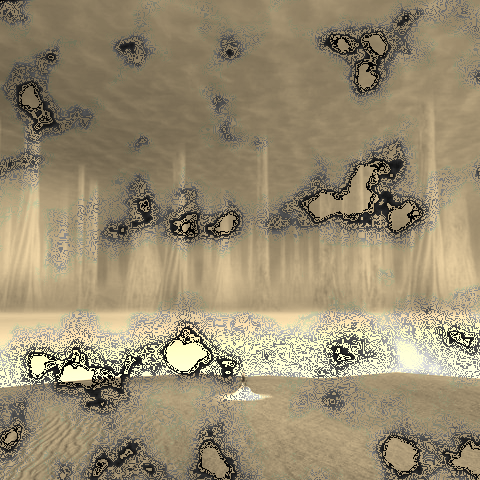

In [363]:
display(Image.fromarray(darken_only(adjust_lighting(arr_c, 5), sepia_filter(B_rb_inv))))

#### (Absolute) Difference:

Subtract one image from the other, and then take the absolute value

In [371]:
abs_diff = lambda arr1, arr2: np.uint8(np.abs(np.float64(arr1) - np.float64(arr2)))

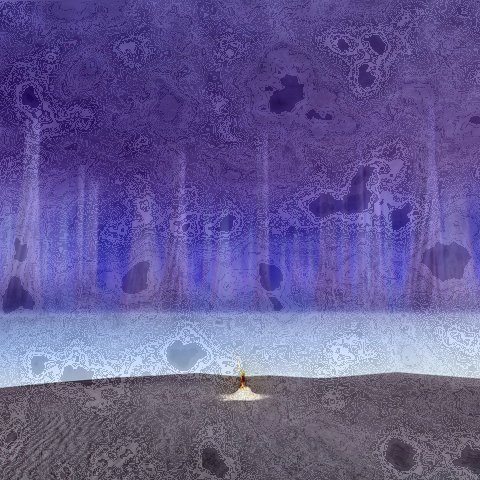

In [373]:
weight = 0.4
Image.fromarray(abs_diff(B_rb_inv, weight*arr_c))

#### Color Dodge:

In [814]:
def color_dodge(arr1, arr2):
    arr_cd = (255*np.float64(arr1))/(255 - np.float64(arr2))
    arr_cd[arr_cd > 255] = 255
    arr_cd[arr_cd < 0] = 0
    return np.uint8(arr_cd)

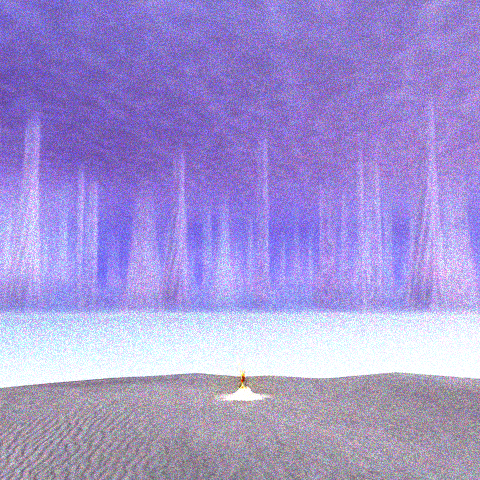

In [816]:
weight = 0.4 #lower the intensity of the noise
B_cd = color_dodge(B_rb_inv, weight*R_color2)
Image.fromarray(B_cd)

#### Color Burn:

In [379]:
def color_burn(arr1,arr2):
    arr_cb = 1- (255 - np.float64(arr1))/(np.float64(arr2))
    arr_cb *= 255
    arr_cb[arr_cb > 255] = 255
    arr_cb[arr_cb < 0] = 0
    return np.uint8(arr_cb)

C:\Users\lukea\AppData\Local\Temp\ipykernel_24172\4237971857.py:2: RuntimeWarning: divide by zero encountered in divide
  arr_cb = 1- (255 - np.float64(arr1))/(np.float64(arr2))
C:\Users\lukea\AppData\Local\Temp\ipykernel_24172\4237971857.py:2: RuntimeWarning: invalid value encountered in divide
  arr_cb = 1- (255 - np.float64(arr1))/(np.float64(arr2))
C:\Users\lukea\AppData\Local\Temp\ipykernel_24172\4237971857.py:6: RuntimeWarning: invalid value encountered in cast
  return np.uint8(arr_cb)


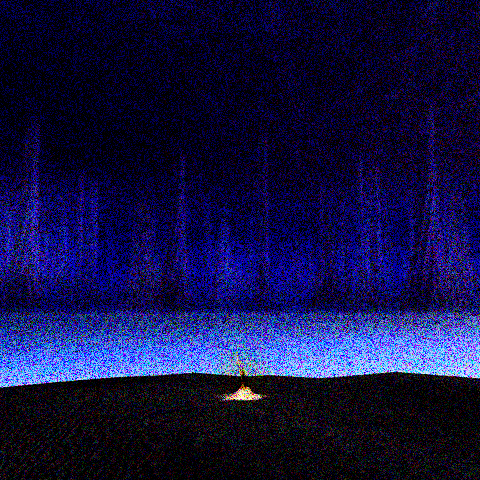

In [381]:
weight = 0.7 #lower the intensity of the noise
B_cb = color_burn(B_rb_inv, weight*R_color2)
Image.fromarray(B_cb)

C:\Users\lukea\AppData\Local\Temp\ipykernel_24172\4237971857.py:2: RuntimeWarning: divide by zero encountered in divide
  arr_cb = 1- (255 - np.float64(arr1))/(np.float64(arr2))
C:\Users\lukea\AppData\Local\Temp\ipykernel_24172\4237971857.py:2: RuntimeWarning: invalid value encountered in divide
  arr_cb = 1- (255 - np.float64(arr1))/(np.float64(arr2))
C:\Users\lukea\AppData\Local\Temp\ipykernel_24172\4237971857.py:6: RuntimeWarning: invalid value encountered in cast
  return np.uint8(arr_cb)


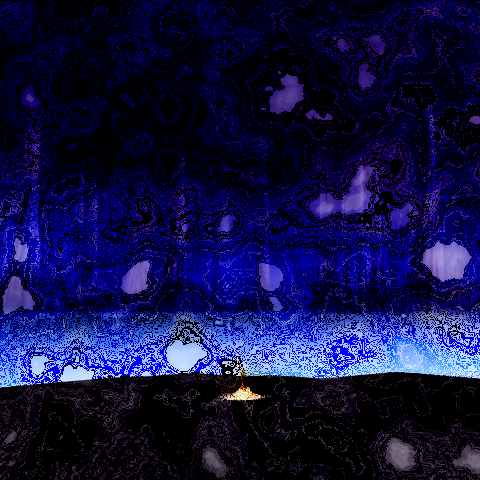

In [383]:
weight = 1.25
B_cb2 = color_burn(B_rb_inv, weight*arr_c)
Image.fromarray(B_cb2)

### Combine gradient filters with blend modes

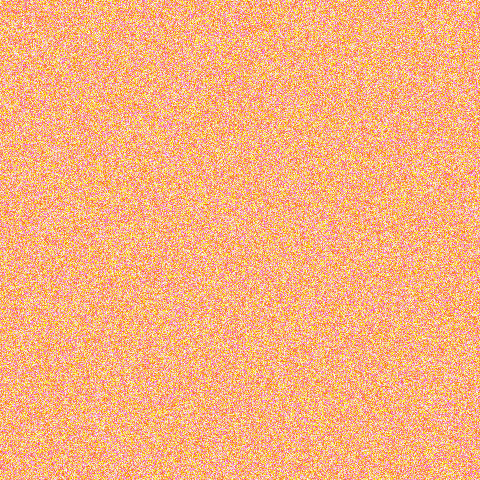

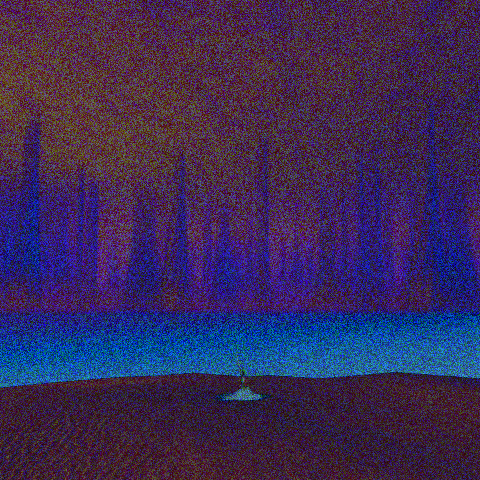

In [396]:
R_creamsicle = gradient_filter(np.uint8(R_color2), Creamsicle_gradient)
display(Image.fromarray(R_creamsicle))
weight = 0.75
display(Image.fromarray(abs_diff(B_rb_inv, weight*R_creamsicle)))

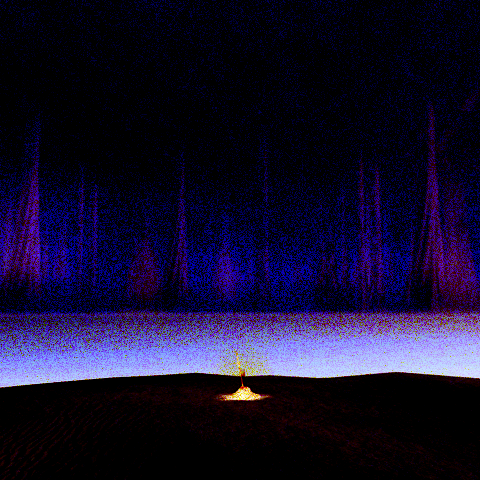

In [390]:
display(Image.fromarray(color_burn(B_rb_inv, 0.5*R_creamsicle)))

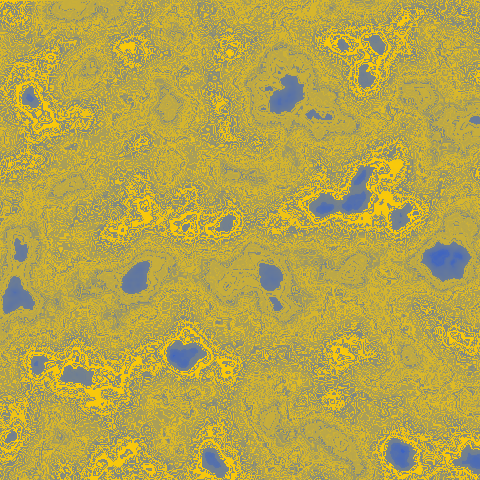

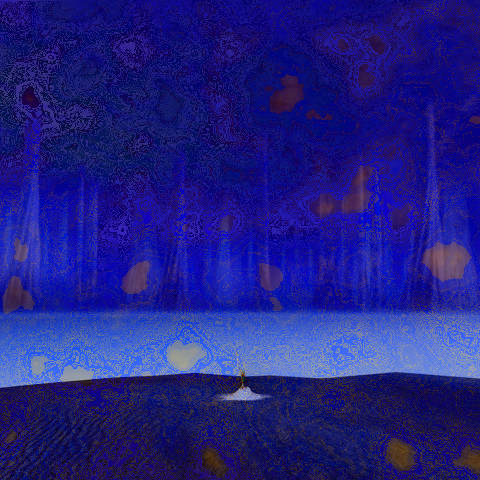

In [375]:
arr_c_UCI = gradient_filter(np.uint8(arr_c), UCI_gradient)
display(Image.fromarray(arr_c_UCI))
display(Image.fromarray(abs_diff(B_rb_inv, 0.6*arr_c_UCI)))

## More photo manipulation effects

Many photo manipulation and image generation effects can be readily broadcast across the array of an image, pixel-by-pixel. Some of the above techniques are used directly by Photoshop.

Many more techniques rely on the pixels surrounding the individual pixel, such as blurring an image, sharpening an image, or edge detection. <a href = https://github.com/smithla-math/UCI_MATH_10/blob/master/homework/Homework4/homework_4.ipynb> Hints for these ideas can be found in Math 10 (an old Summer 2022 homework assignment) </a>.

## Bonus: Art Sandbox

I've included all of my custom art functions from this lecture in the cell below, for convenience of experimentation. All you need to do is run the cell below once.

For the effects, all outputs are stored as arrays. This is the most efficient way to combine multiple effects.

Be sure to use `Image.open` to access an image, `np.asaray` to convert it into an array `Image.fromarray` once you want to see the result of your filter(s)

In [496]:
import numpy as np
import os
from PIL import Image

img = Image.open("ash-lake.png")
arr = np.asarray(img)


def save_anim(anim_frames,filename, dur=100): #must include .gif extension in filename
    anim_frames[0].save(
            filename,
            save_all=True,
            append_images=anim_frames[1:],  # Append the rest of the frames
            duration=dur,              # Duration of each frame in milliseconds
            loop=0                     # 0 means loop indefinitely
        )

weighted_average = lambda weight, arr1, arr2: np.uint8((1-weight)*arr1 + weight*arr2)

def transparent_layer(weight, mask_color, arr_bg, arr_transp):
    bool = arr_transp == mask_color  #mask will be the color we replace
    arr_transp2 = arr_transp.copy()
    arr_transp2[bool] = arr_bg[bool]
    arr_averaged = weighted_average(weight, arr_bg, arr_transp2)
    return arr_averaged

def channel_swap(arr, swap):
    B = arr.copy()
    B[:,:,0] = arr[:,:,swap[0]]
    B[:,:,1] = arr[:,:,swap[1]]
    B[:,:,2] = arr[:,:,swap[2]]
    return B

def invert_colors(arr):
    B = arr.copy()
    B = 255 - B
    return B

def generalized_invert_colors(arr, C):  
    B = arr.copy()
    B = C - B #subtract C from B, instead of 255 from B
    return np.uint8(B)

def adjust_lighting(arr, c):
    L = np.float64(arr.copy())
    L = c*L
    L[L > 255] = 255
    return np.uint8(L)

grayscale = lambda arr: np.uint8(0.2125*Y[:,:,0] + 0.7154*Y[:,:,1] + 0.0721*Y[:,:,2])  #function version

def sepia_filter(S):
    S_sepia = np.float64(np.zeros_like(S))
    S_sepia[:,:,0] = 0.393*S[:,:,0] + 0.769*S[:,:,1] + 0.189*S[:,:,2]
    S_sepia[:,:,1] = 0.349*S[:,:,0] + 0.686*S[:,:,1] + 0.168*S[:,:,2]
    S_sepia[:,:,2] = 0.272*S[:,:,0] + 0.534*S[:,:,1] + 0.131*S[:,:,2]
    
    S_sepia[S_sepia > 255] = 255
    return np.uint8(S_sepia)

lighten_only = lambda arr1, arr2: np.uint8(np.maximum(arr1, arr2))

darken_only = lambda arr1, arr2: np.uint8(np.minimum(arr1, arr2))

abs_diff = lambda arr1, arr2: np.uint8(np.abs(np.float64(arr1) - np.float64(arr2)))

def duotone_gradient(color1, color2):
    Duo_gradient = np.zeros((256, 3))
    
    for i in range(3):
        Duo_gradient[:, i] = np.linspace(color1[i], color2[i], 256)
    return np.uint8(Duo_gradient)

def gradient_filter(D, gradient):
    Du = D.copy()
    D_gray = grayscale(Du)
    for channel in range(3):
        Mask = np.ones_like(D_gray).reshape(D.shape[0],D.shape[1])
        for color in range(Du.min(), Du.max()+1):
            Mask[(Mask == 1) & (Du[:,:,channel] == color)] = 2  #flags any channel that matches the color in that channel
            Du[:,:,channel][(Du[:,:,channel] == color) & (Mask == 2)] = gradient[color,channel]  #changes the colors according to which channels are flagged.
            Mask[Mask == 2] = 0 #Mark these channels as no longer needing to be changed.
    return np.uint8(Du)

def gradient_filter_v2(D, color1, color2):
    Du = D.copy()
    D_gray = grayscale(Du)
    gradient = duotone_gradient(color1, color2)
    for channel in range(3):
        Mask = np.ones_like(D_gray).reshape(D.shape[0],D.shape[1])
        for color in range(Du.min(), Du.max()+1):
            Mask[(Mask == 1) & (Du[:,:,channel] == color)] = 2  #flags any channel that matches the color in that channel
            Du[:,:,channel][(Du[:,:,channel] == color) & (Mask == 2)] = gradient[color,channel]  #changes the colors according to which channels are flagged.
            Mask[Mask == 2] = 0 #Mark these channels as no longer needing to be changed.
    return np.uint8(Du)


def color_dodge(arr1, arr2):
    arr_cd = (255*np.float64(arr1))/(255 - np.float64(arr2))
    arr_cd[arr_cd > 255] = 255
    arr_cd[arr_cd < 0] = 0
    return np.uint8(arr_cd)

def color_burn(arr1,arr2):
    arr_cb = 1- (255 - np.float64(arr1))/(np.float64(arr2))
    arr_cb *= 255
    arr_cb[arr_cb > 255] = 255
    arr_cb[arr_cb < 0] = 0
    return np.uint8(arr_cb)